## Exploração da Geometria de *embeddings* jurídicos.

**Aluno**: Ricardo Kaê de Souza Bloise (TCC IC-UFRJ 2026).

**Título**: Uma análise comparativa e preliminar entre geometrias de espaços
de *embeddings* contextuais sob modelos tradicionais de Aprendizado de Máquina,
no contexto jurídico.

**Orientação**: Carolina Gil Marcelino, João Luiz Lagoas.

---

Nesse laboratório, aplica-se técnicas tradicionais de ML para explorar
a geometria de espaços de *embeddings* contextuais, gerados sob modelos
Transformer, a partir de amostras jurídicas (dados do STJ).

Tradicionalmente, aplica-se:
* **Técnicas não supervisionadas**, como:
  * Redução de dimensionalidade via *t-SNE*.
  * Qualificação de complexidade na organização de um espaço via métrica de *silhouette*.
* **Classificadores supervisionados**, como: (k-NN, regLog, MLP, SVM) para
separar amostras jurídicas (*special appeals*) em temas judiciais. Nesse sentido, adota-se a seguinte abordagem avaliativa:
    * Validação de modelos com base em uma busca exaustiva de hiperparâmetros definidos sob um *grid* de possibilidades, segundo a técnica *GridSearchCV*.
    * Estimação para a capacidade de generalização (tanto em dados de teste quanto de validação), a partir das técnicas de *holdout* e *10-fold stratified cross validation*, com base nas métricas: *F1-macro* e *acurácia*.
    * Computação de um procedimento estatístico básico para indicar a natureza da separabilidade de um espaço com base na diferença entre métricas médias de performance de grupos de classificadores.

### Experimentos.
Para experimentação, cinco cenários foram definidos, para estudar a geometria dos espaços de representação, tanto para comparar um espaço com outro, quanto para comparar os diferentes cenários de experimentos, uma vez que alguns são definidos com base em outros.


### Ambiente

In [ ]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
# Instalação dos pacotes abaixos nas suas respectivas versões necessárias
!pip install transformers==4.44.2 sentence-transformers==3.1.1 peft==0.12.0 einops -qqq

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.3/245.3 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.4/296.4 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 61.0 MB/s eta 0:00:00


In [ ]:
# Bibliotecas

# Básicas para Computação
import time
import gc
from importlib.metadata import version

# Fundamentais: AlgLin, GeoAna, Numerical
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# NLP: Pré-processamento de texto
import string, re
import nltk
from nltk.corpus import stopwords

# Self-supervised: Modelos Transformer
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import SentenceTransformer

# Uso de GPU
import torch
import torch.nn.functional as F

# Unsupervised: Redução de dimensionalidade
from sklearn.manifold import TSNE
#from mpl_toolkits.mplot3d import Axes3D

# Supervised: Classificadores
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC, LinearSVC

# Validação Cruzada
from sklearn.model_selection import StratifiedKFold, \
                    cross_validate, cross_val_score, \
                      train_test_split, GridSearchCV

# Transformação de dados
from sklearn.preprocessing import StandardScaler
#from sklearn.preprocessing import LabelEncoder

# Métricas de avaliação
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import confusion_matrix, classification_report, \
                            ConfusionMatrixDisplay, f1_score, \
                            accuracy_score, precision_score, \
                            recall_score, silhouette_score, \
                            make_scorer


# Automação
from sklearn.pipeline import make_pipeline
from sklearn.pipeline import Pipeline

# Exceções
import warnings
from sklearn.exceptions import ConvergenceWarning

In [ ]:
# Versões das libraries
print("Transformers:", version("transformers"))
print("Sentence-Transformers:", version("sentence-transformers"))
print("numpy",version("numpy"))
print("pandas",version("pandas"))
print("matplotlib",version("matplotlib"))
print("nltk",version("nltk"))
print("scikit-learn", version("scikit-learn"))

Transformers: 4.44.2
Sentence-Transformers: 3.1.1
numpy 2.0.2
pandas 2.2.2
matplotlib 3.10.0
nltk 3.9.1
scikit-learn 1.6.1


In [ ]:
# Leitura dos datasets
sappeal = pd.read_csv('special_appeal.csv', encoding = 'utf-8')
themes = pd.read_csv("themes.csv")

### Análise do dataset sappeal

In [ ]:
# Resumo estrutural do dataset de special_appeals
sappeal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7967 entries, 0 to 7966
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   theme_id             7967 non-null   int64 
 1   special_appeal_text  7967 non-null   object
dtypes: int64(1), object(1)
memory usage: 124.6+ KB


In [ ]:
# Primeiras instâncias do dataset de special_appeals
sappeal.head(2)

,theme_id,special_appeal_text
0,1150,"cabimento recurso análise autos, verifica-se:)..."
1,1150,cabimento recurso especial constituição prevê ...


In [ ]:
# Amostras aleatórias do dataset de special_appeals
sappeal.sample(10)

,theme_id,special_appeal_text
4492,1057,"cabimento recurso art . 1.029 cpc,, determina ..."
2599,1176,. . estado / . n.º 5009656.29.2022.4.02.000...
2398,3,"cabimento recurso art . 1.029 cpc,, determina ..."
6751,694,"& sociedade - / mg 2.921 exmo . . 2a, devid..."
1343,7,"cabimento recurso art . 1.029 cpc,, determina ..."
3082,1125,cabimento recurso tela . 7 decerto questões en...
1156,11,. n.º autor: réu: instituto nacional seguro ...
799,11,"cabimento presente recurso, voltado corrigir o..."
6456,962,"cabimento s tanto execução quanto embargos, po..."
2723,1164,cabimento presente recurso extraordinário 8 . ...


In [ ]:
# Resumo estatístico das palavras de cada texto/document do dataset
ws_sappeal = sappeal["special_appeal_text"].str.split().str.len()
# Estatísticas
print("Média de palavras por texto:", ws_sappeal.mean())
print("Quantidade mediana de palavras por texto:", ws_sappeal.median())
print("Mínima quantidade de palavras por texto:", ws_sappeal.min())
print("Máxima quantidade de palavras por texto:", ws_sappeal.max())

Média de palavras por texto: 2496.122379816744
Quantidade mediana de palavras por texto: 2133.0
Mínima quantidade de palavras por texto: 21
Máxima quantidade de palavras por texto: 39121


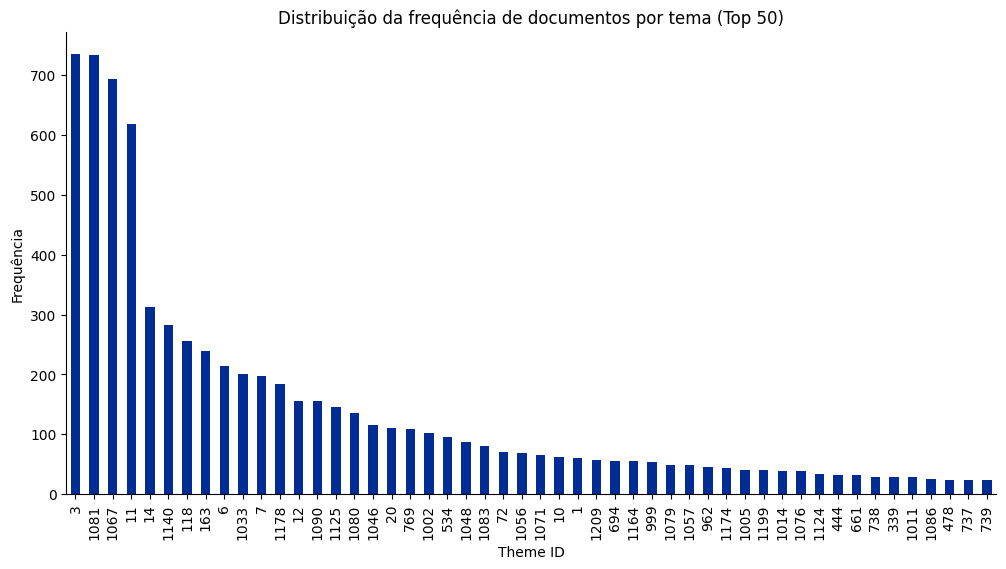

In [ ]:
# Distribuição inicial (antes de preprocessing) das classes do dataset
dinicial_classes = sappeal["theme_id"].value_counts()
# Extração das 50 maiores classes (com maior qnt de docs/textos associados )
dinicial_top50 = dinicial_classes.head(50)
# Plot
dinicial_top50.plot(kind="bar", figsize=(12,6),  color="#002c94")
# Configurações do plot
plt.title("Distribuição da frequência de documentos por tema (Top 50)")
plt.xlabel("Theme ID")
plt.ylabel("Frequência")
plt.xticks(rotation=90)
# Axis
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Download do gráfico
plt.savefig("fig_dinicial.pdf", bbox_inches="tight")
# Exibição do Gráfico
plt.show()

### Pré-processamento do dataset sappeal

#### Remoção de duplicatas


In [ ]:
# Dataset contendo apenas as duplicatas de special_appeals
sappeal_dup = sappeal[sappeal.duplicated(keep='first')]

# Instâncias duplicadas do dataset
amostras_dup = pd.concat([sappeal_dup.head(5),
                          sappeal_dup.sample(20, random_state=42),
                          sappeal_dup.tail(5)
])
amostras_dup.sample(10)

,theme_id,special_appeal_text
13,14,cabimento recurso especial . caracterização qu...
2156,3,cabimento cuida-se julgado negou transito reme...
1942,3,"cabimento recurso art . 1.029 cpc,, determina ..."
12,14,cabimento recurso especial . caracterização qu...
7209,444,cabimento recurso especial análise autos resta...
7405,72,cabimento recurso 3 . autora interpôs recurso ...
5264,1067,cabimento recurso especial: análise autos rest...
18,14,"doutor 2ª . / : : , jurídica direito púb..."
7965,163,"cabimento:) violação art . 1.022, ii cpc expos..."
2145,3,cabimento cuida-se julgado negou transito reme...


In [ ]:
# Quantidade de duplicatas
sappeal_dup.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3422 entries, 12 to 7965
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   theme_id             3422 non-null   int64 
 1   special_appeal_text  3422 non-null   object
dtypes: int64(1), object(1)
memory usage: 80.2+ KB


In [ ]:
# Remove duplicatas de texto no dataset sappeal
sappeal_nodup = sappeal.drop_duplicates()

In [ ]:
# Informações do dataset sem duplicatas
sappeal_nodup.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4545 entries, 0 to 7966
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   theme_id             4545 non-null   int64 
 1   special_appeal_text  4545 non-null   object
dtypes: int64(1), object(1)
memory usage: 106.5+ KB


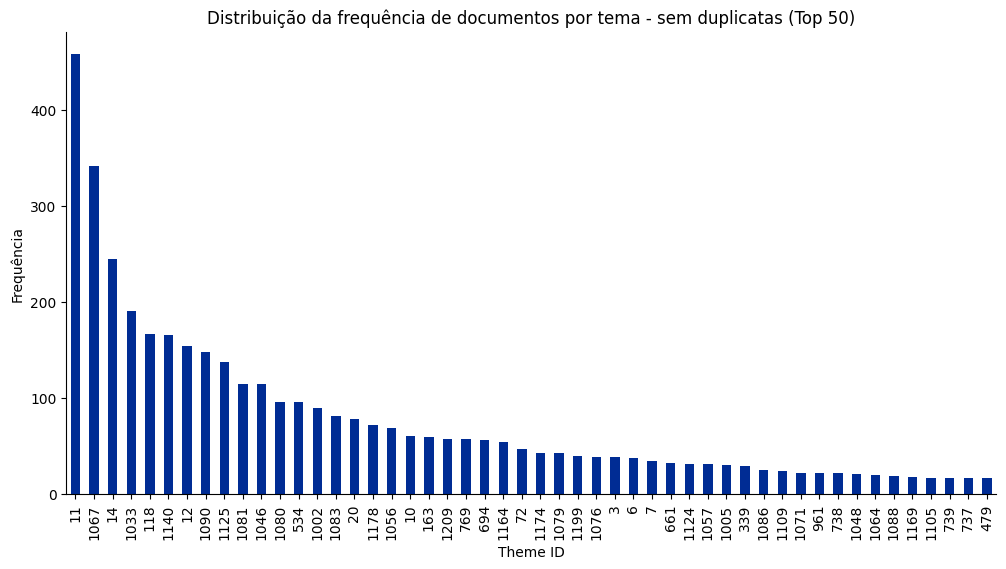

In [ ]:
# Distribuição da quantidade de documentos por temas do dataset sem duplicatas
classes_nodup = sappeal_nodup["theme_id"].value_counts()
# Extração das 50 maiores classes (com maior qnt de docs/textos associados )
dnodup_top50 = classes_nodup.head(50)
# Plot
dnodup_top50.plot(kind="bar", figsize=(12,6), color="#002c94")
# Configurações do plot
plt.title("Distribuição da frequência de documentos por tema - sem duplicatas (Top 50)")
plt.xlabel("Theme ID")
plt.ylabel("Frequência")
plt.xticks(rotation=90)
# Axis
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# Download do gráfico
plt.savefig("fig_dnodup.pdf", bbox_inches="tight")
# Exibição do Gráfico
plt.show()

#### Pré-processamento de texto

- Transformação *lower-case*
- Remoção de números, caracteres especiais, sinais de pontuação e *stopwords*.

In [ ]:
nltk.download('stopwords')
stopwords = nltk.corpus.stopwords.words('portuguese')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
# Função para limpar o texto do dataset
def cleaning(text):

    # minúsculas
    text = text.lower()

    # remover números
    text = re.sub(r'\d+', '', text)

    # remover sinais de pontuação
    text = text.translate(str.maketrans('', '', string.punctuation))

    # remover caracteres especiais
    text = re.sub(r'[^a-zà-ú\s]', '', text)

    # remover stopwords
    tokens = text.split()
    tokens = [word for word in tokens if word not in stopwords]

    return " ".join(tokens)

In [ ]:
# Aplica a função cleaning no dataset
sappeal_clean = sappeal_nodup.copy()
sappeal_clean["clean_text"] = sappeal["special_appeal_text"].apply(cleaning)

In [ ]:
# Algumas amostras do dataset limpo
sappeal_clean.sample(20)

,theme_id,special_appeal_text,clean_text
2983,1140,"cabimento recurso, entende recorrente decisões...",cabimento recurso entende recorrente decisões ...
7192,315,cabimento recurso extraordinário constituição ...,cabimento recurso extraordinário constituição ...
1109,11,. n.º autor: fajardo réu: instituto nacional...,n autor fajardo réu instituto nacional seguro ...
4492,1057,"cabimento recurso art . 1.029 cpc,, determina ...",cabimento recurso art cpc determina recorrente...
7210,444,cabimento recurso especial análise autos resta...,cabimento recurso especial análise autos resta...
6106,1002,"doutor, n / defensoria pública , diante leg...",doutor n defensoria pública diante legitimidad...
632,12,cabimento presente recurso cumpre salientar pr...,cabimento presente recurso cumpre salientar pr...
3275,1105,"cabimento recurso termos art . 1.029,, cabe re...",cabimento recurso termos art cabe recorrente d...
6300,769,"cabimento - violação artigos 797, 805, 835, i ...",cabimento violação artigos i cpc artigos i ii ...
6907,1090,passos desenbargador dotribunal 2a requerente:...,passos desenbargador dotribunal requerente req...


### Análise do dataset themes


In [ ]:
# Resumo estrutural do dataset themes
themes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   theme_text  187 non-null    object
 1   theme_id    187 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.1+ KB


In [ ]:
# Amostras inicias do dataset themes
themes.head(2)

,theme_text,theme_id
0,Definir o âmbito de aplicação do artigo 112 da...,1
1,Definir a respeito da dispensa ou não do reexa...,3


In [ ]:
# Amostras aleatórias do dataset themes
themes.sample(2)

,theme_text,theme_id
87,Natureza jurídica de direitos: se individuais ...,861
96,Constitucionalidade da Contribuição de Interve...,914


In [ ]:
# Resumo estatístico das palavras de cada instância do dataset themes
ws_themes = themes["theme_text"].str.split().str.len()
# Estatísticas
print("Média de palavras por texto:", ws_themes.mean())
print("Quantidade mediana de palavras por texto:", ws_themes.median())
print("Mínima quantidade de palavras por texto:", ws_themes.min())
print("Máxima quantidade de palavras por texto:", ws_themes.max())

Média de palavras por texto: 42.53475935828877
Quantidade mediana de palavras por texto: 35.0
Mínima quantidade de palavras por texto: 6
Máxima quantidade de palavras por texto: 300


In [ ]:
# Modelo Transformer no contexto jurídico para calculo de similaridade
BERT_PT_legal = "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0"
BERT_PT_legal = SentenceTransformer(BERT_PT_legal)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Invalid model-index. Not loading eval results into CardData.


config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Invalid model-index. Not loading eval results into CardData.


In [ ]:
# Exemplo de matriz de similaridade entre o texto plano de temas judiciais

# Embeddings dos temas 3 e 1081, segundo o modelo STJ-iris-BERTLegal
tema3 = themes[themes['theme_id'] == 3]["theme_text"].iloc[0]
tema1081 = themes[themes['theme_id'] == 1081]["theme_text"].iloc[0]
emb_3_1081 = BERT_PT_legal.encode([tema3, tema1081])
# Matriz de similaridade entre os temas 3 e 1081
similarity_3_1081_matrix = cosine_similarity(emb_3_1081)
pd.DataFrame(similarity_3_1081_matrix,
             index=["3", "1081"], columns=["3", "1081"])

,3,1081
3,1.000000,0.764663
1081,0.764663,1.000000


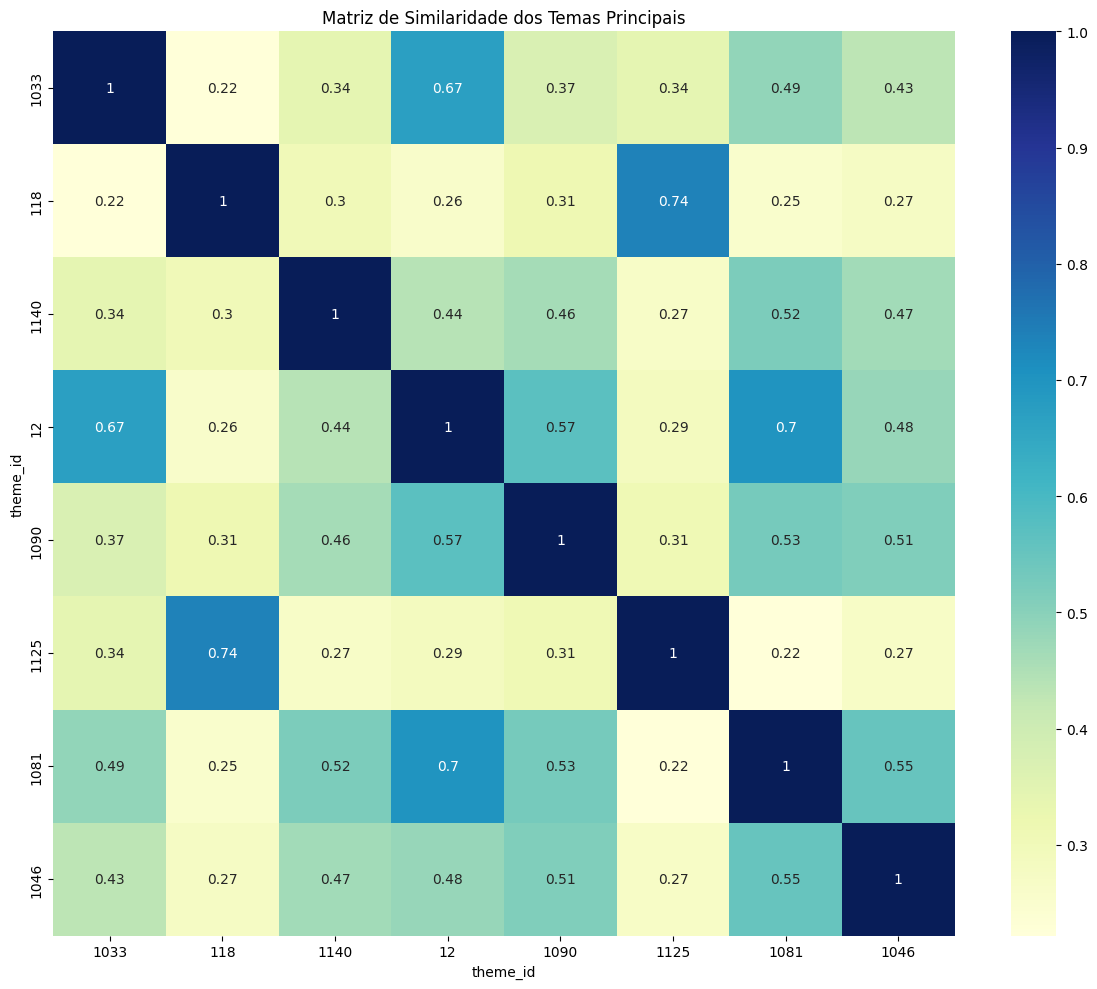

In [ ]:
# Matriz de Similaridade dos Temas Principais

# Seleção dos temas mais frequentes do dataset limpo
temas = sappeal_nodup["theme_id"].value_counts().head(11).index.tolist()
top_themes = themes[themes['theme_id'].isin(temas)]
# ordenação dos top temas
top_themes = top_themes.set_index('theme_id').loc[temas].reset_index()

# Recuperação dos textos e IDs dos top_themes
themes_text = top_themes['theme_text'].tolist()[3:]
themes_ids = top_themes['theme_id'].tolist()[3:]

# Geração de Embeddings do texto plano dos temas
emb_bert_lgl = BERT_PT_legal.encode(themes_text)

# Matriz de similaridade (via cosseno) dos embeddings dos temas
similarity_matrix = cosine_similarity(emb_bert_lgl)

# Transformação em DataFrame com índices e colunas = themes_id
similarity_df = pd.DataFrame(similarity_matrix,
                             index=themes_ids, columns=themes_ids)

# Plotar a matriz de similaridade segundo um mapa de calor
plt.figure(figsize=(12,10))

# Heatmap com valores entre 0 e 1
sns.heatmap(similarity_df,
            cmap='YlGnBu',   # cores do mapa
            annot=True,      # True para mostrar números nas células
            xticklabels=themes_ids,
            yticklabels=themes_ids)

plt.title("Matriz de Similaridade dos Temas Principais")
plt.xlabel("theme_id")
plt.ylabel("theme_id")
plt.tight_layout()

# Download do gráfico
plt.savefig("fig_mSim.pdf", bbox_inches="tight")

plt.show()

### **Modelos Transformer**

| Modelo | Dimensão | Contexto | Parâmetros | Idioma |
|--------|----------|---------|-----------|--------|
| jinaai/jina-embeddings-v3 | 1024 | 8192 tokens | ~570M | Multilíngue (100+) |
| BAAI/bge-m3 | 1024 | 8192 tokens | ~568M | Multilíngue (100+) |
| stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0 | 1024 | 514 tokens | ~335M | Português jurídico |
| PORTULAN/serafim-335m-portuguese-pt-sentence-encoder | 1024 | 128 tokens | ~335M | Português PT |

In [ ]:
# Gera Embeddings segundo modelos Transformer (Huggings Face)
def gera_embeddings(df, text, model_hf, batch = 4):
    # Detecta dispositivo de processamento automaticamente
    device = "cuda" if torch.cuda.is_available() else "cpu"

    print("Gerando embeddings no modelo: ", model_hf)

    # Carrega o modelo do Huggings Face no dispositivo
    model = SentenceTransformer(model_hf, device=device,
                                  trust_remote_code=True)

    # Extrai os textos do dataframe
    textos = df[text].astype(str).tolist()

    # Marcação do tempo - liga o cronometro
    #torch.cuda.synchronize()
    inicio = time.time()

    # Gera embeddings usando GPU
    embeddings = model.encode(
        textos,
        batch_size=batch,
        convert_to_numpy=True,
        show_progress_bar=True,
        device=device,
    )

    # desliga o cronometro
    #torch.cuda.synchronize()
    fim = time.time()
    print("Tempo:", f"{fim-inicio:.2f}segundos")

    # Limpeza de memória
    del model
    gc.collect()
    #torch.cuda.empty_cache()
    #torch.cuda.ipc_collect()

    return embeddings

In [ ]:
def smean_inter(X, y):
    S = cosine_similarity(X)
    classes = np.unique(y)
    resultados = []

    for i, classe1 in enumerate(classes):
        for j, classe2 in enumerate(classes):

            # Evita calcular classe consigo mesma
            # e evita repetir A-B e B-A
            if i < j:

                # Índices dos documentos de cada classe
                idx1 = np.where(y == classe1)[0]
                idx2 = np.where(y == classe2)[0]

                # Similaridades entre documentos das duas classes
                pares = S[np.ix_(idx1, idx2)]

                # Média das similaridades
                media = pares.mean()

                resultados.append({
                    "classe_1": classe1,
                    "classe_2": classe2,
                    "n_pares": pares.size,
                    "similaridade_media": media
                })

    return pd.DataFrame(resultados)

### Técnicas não supervisionadas

* Redução de dimensionalidade (t-SNE)
* Avaliação de *clusters* (índice de silhouette)

In [ ]:
def indice_silhouette(embeddings, labels):
    X = np.vstack(embeddings)
    y = labels
    return  silhouette_score(X, y)

In [ ]:
# Aplica t-SNE para projetar embeddings em 2 dimensões
def reduzir_dimensionalidade(df, emb_col, label_col, title):

    # Extrai embeddings e rótulos
    X = np.vstack(df[emb_col].values)
    y = df[label_col].values

    # Aplica t-SNE
    reducer = TSNE(
        n_components=2,
        random_state=42,
        perplexity=30,
        max_iter=1000
    )

    X_red = reducer.fit_transform(X)

    # Plot
    plt.figure(figsize=(8, 6))

    classes = np.unique(y)

    for classe in classes:

        idx = y == classe

        plt.scatter(
            X_red[idx, 0],
            X_red[idx, 1],
            label=classe,
            alpha=0.7
        )

    # Configura gráfico
    plt.xlabel("Dimensão 1")
    plt.ylabel("Dimensão 2")
    plt.title(f"{title} (t-SNE)")
    plt.legend()
    plt.grid(True)

    # Download do gráfico
    plt.savefig(title + ".pdf", bbox_inches="tight")

    plt.show()

### Classificadores Supervisionados

- *Grid* de hiperparâmetros para *GridSearchCV* sob métrica
$F1$-*macro*
- Função classifica, com:
  - holdout 80/20
  - 10-*fold stratified cross validation*
  - métricas: acurácia, $F1$-*macro* por espaço de *embeddings*

In [ ]:
# Modelos com suas respectivas grades de hiperparametros
modelos = {

    "RegLog": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                penalty="l2",
                max_iter=2000
            ))
        ]),
        {
            "clf__C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "SVM-LIN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearSVC())
        ]),
        {
            "clf__C": [0.1, 1, 10, 100]
        }
    ),

    "k-NN": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier())
        ]),
        {
            "clf__n_neighbors": [3, 5, 7, 11, 15],
            "clf__weights": ["uniform", "distance"]
        }
    ),

  "MLP": (
    Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(
            max_iter=2000
        ))
    ]),
    {
        "clf__hidden_layer_sizes": [
            (10,),
            (20),
            (10, 10),
            (50,),
            (128,),
            (256,)
        ],
        "clf__activation": [
            "logistic",   # Sigmoide
            "relu"
        ],
        "clf__alpha": [
            1e-4,
            1e-3,
            1e-2
        ]
    }
),

    "SVM-RBF": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf"))
        ]),
        {
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", "auto"]
        }
    )
}

In [ ]:
def classificar(X, y, modelos, n_execucoes=15):

    # Filtra warnings de convergencia
    warnings.filterwarnings("ignore", category=ConvergenceWarning)

    resultados = []
    melhores_params = {}

    # Holdout inicial para seleção dos hiperparâmetros
    X_train, X_val, y_train, y_val = train_test_split(
        X, y,
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    # Validação cruzada para seleção dos hiperparâmetros
    cv = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )

    # Busca hiperparâmetros que levam a uma avaliação mais robusta
    modelos_otimizados = {}

    for nome, (modelo, grid) in modelos.items():

        busca = GridSearchCV(
            modelo,
            grid,
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            refit=True
        )

        busca.fit(X_train, y_train)

        modelos_otimizados[nome] = busca.best_estimator_
        melhores_params[nome] = busca.best_params_

    # Avalia os modelos validados 15 vezes
    for execucao in range(n_execucoes):

        seed = 42 + execucao

        # Novo holdout estratificado para avaliação
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.20,
            stratify=y,
            random_state=seed
        )

        for nome, modelo in modelos_otimizados.items():

            inicio = time.perf_counter()

            # Treina o modelo com hiperparâmetros fixados
            modelo.fit(X_train, y_train)

            # Avalia no conjunto de teste
            y_pred = modelo.predict(X_test)

            tempo = time.perf_counter() - inicio

            # Armazena os resultados
            resultados.append({
                "Modelo": nome,
                "F1-macro": f1_score(
                    y_test, y_pred, average="macro"
                ),
                "Acurácia": accuracy_score(
                    y_test, y_pred
                ),
                "Tempo": tempo
            })

    # Converte os resultados para DataFrame
    df = pd.DataFrame(resultados)

    # Calcula média e desvio-padrão
    resumo = df.groupby("Modelo").agg(
        F1_macro_media=("F1-macro", "mean"),
        F1_macro_std=("F1-macro", "std"),
        Acuracia_media=("Acurácia", "mean"),
        Acuracia_std=("Acurácia", "std"),
        Tempo_medio=("Tempo", "mean"),
        Tempo_std=("Tempo", "std")
    )

    # Formata a tabela final
    tabela = pd.DataFrame(index=resumo.index)

    tabela["F1-macro"] = (
        resumo["F1_macro_media"].round(4).astype(str)
        + " ± "
        + resumo["F1_macro_std"].round(4).astype(str)
    )

    tabela["Acurácia"] = (
        resumo["Acuracia_media"].round(4).astype(str)
        + " ± "
        + resumo["Acuracia_std"].round(4).astype(str)
    )

    tabela["Tempo (s)"] = (
        resumo["Tempo_medio"].round(2).astype(str)
        + " ± "
        + resumo["Tempo_std"].round(2).astype(str)
    )

    return tabela, df, melhores_params

In [ ]:
# Define o processo estatístico com base na diferença entre a media dos grupos.
def processo_estatistico(df, limiar_f1=0.75, limiar_delta=0.05):

    # Define os grupos de classificadores
    lineares = ["RegLog", "SVM-LIN"]
    nao_lineares = ["k-NN", "SVM-RBF", "MLP"]

    # Calcula a performance média de cada classificador
    medias = df.groupby("Modelo")["F1-macro"].mean()

    # Média dos modelos lineares
    m_L = medias.loc[lineares].mean()

    # Média dos modelos não lineares
    m_NL = medias.loc[nao_lineares].mean()

    # Diferença entre os grupos
    delta = m_NL - m_L

    # Interpretação da diferença
    if delta > limiar_delta and m_NL >= limiar_f1:
        interpretacao = (
            "Indicação empírica de estrutura discriminativa "
            "predominantemente não linear."
        )

    elif delta < -limiar_delta and m_L >= limiar_f1:
        interpretacao = (
            "Indicação empírica de estrutura discriminativa "
            "predominantemente linear."
        )

    elif abs(delta) <= limiar_delta and m_L >= limiar_f1 and m_NL >= limiar_f1:
        interpretacao = (
            "Boa separabilidade dos dados, sem vantagem significativa "
            "entre classificadores lineares e não lineares."
        )

    elif abs(delta) <= limiar_delta and m_L < limiar_f1 and m_NL < limiar_f1:
        interpretacao = (
            "Baixo poder preditivo da representação para os "
            "classificadores avaliados."
        )

    else:
        interpretacao = (
            "Resultado intermediário: há diferença entre os grupos, "
            "mas ela não é suficiente para caracterizar claramente "
            "um regime de separabilidade."
        )

    return {
        "m_L": m_L,
        "m_NL": m_NL,
        "Delta": delta,
        "Interpretacao": interpretacao
    }

### Resultados (Experimentos)

#### Cenário 1: [1033,12,1081] - Similaridade Alta

In [ ]:
# Cenario [1033,12,1081]
df1 = sappeal_clean[sappeal_clean["theme_id"].isin([1033,12,1081])]
df1_sizes = df1.value_counts("theme_id")
display(df1_sizes)
print("\nSize: ", df1.value_counts("theme_id").sum(), "amostras")

In [ ]:
# Impressão do texto plano dos temas do cenario 1
cenario1 = [1033,12,1081]
display(themes[themes["theme_id"].isin(cenario1)][["theme_id", "theme_text"]])

,theme_id,theme_text
10,12,Definir se a liquidação prévia do julgado é re...
122,1033,Interrupção do prazo prescricional para pleite...
143,1081,Definir se a demanda previdenciária cujo valor...


In [ ]:
# Variável de saída do dataframe 1
ydf1 = df1["theme_id"].values

In [ ]:
# Amostras aleatórias do df1
df1.sample(10)

,theme_id,special_appeal_text,clean_text
512,12,cabimento recurso recorrentes asseguram preenc...,cabimento recurso recorrentes asseguram preenc...
4760,1033,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...
4056,1081,cabimento cuida-se julgado negou transito reme...,cabimento cuidase julgado negou transito remes...
564,12,cabimento recurso especial hipótese tela autor...,cabimento recurso especial hipótese tela autor...
4805,1033,cabimento - acordo enunciado 150 jurisprudênci...,cabimento acordo enunciado jurisprudência sumu...
4812,1033,". sr. . ref . proc: falcão outros, autos epí...",sr ref proc falcão outros autos epígrafe litig...
596,12,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...
579,12,"cabimento . aplicação multa . art . 1.021, § 4...",cabimento aplicação multa art código civil des...
4861,1033,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...
573,12,cabimento consabido recurso especial destina-s...,cabimento consabido recurso especial destinase...


##### BGE-M3

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
# emb_df1_bgem3 = gera_embeddings(df1, "clean_text", "BAAI/bge-m3", 1)
# Salvando a matriz de embeddings
# np.save("emb_df1_bge-m3.npy", emb_df1_bgem3)

In [ ]:
# Carrega o modelo de embeddings salvo
df1["BGE-M3"] = list(np.load("emb_df1_bge-m3.npy"))

/tmp/ipykernel_271/967497805.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["BGE-M3"] = list(np.load("emb_df1_bge-m3.npy"))


In [ ]:
# Amostras aleatórias do df1
df1.sample(2)

,theme_id,special_appeal_text,clean_text,BGE-M3
4729,1033,"cabimento, possuindo natureza extraordinária, ...",cabimento possuindo natureza extraordinária me...,"[-0.0159619, 0.060547713, -0.015310928, 0.0289..."
585,12,. . : sindicato trabalhadores educação univer...,sindicato trabalhadores educação universidade ...,"[-0.047726605, 0.018215975, 0.0058329157, -0.0..."


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf1_bge = np.vstack(df1["BGE-M3"].values)

In [ ]:
# Cálculo da similaridade média entre documentos no espaço BGE-M3
smean_inter(Xdf1_bge,ydf1)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.805076
1,12,1081,17710,0.764699
2,1033,1081,21965,0.750942


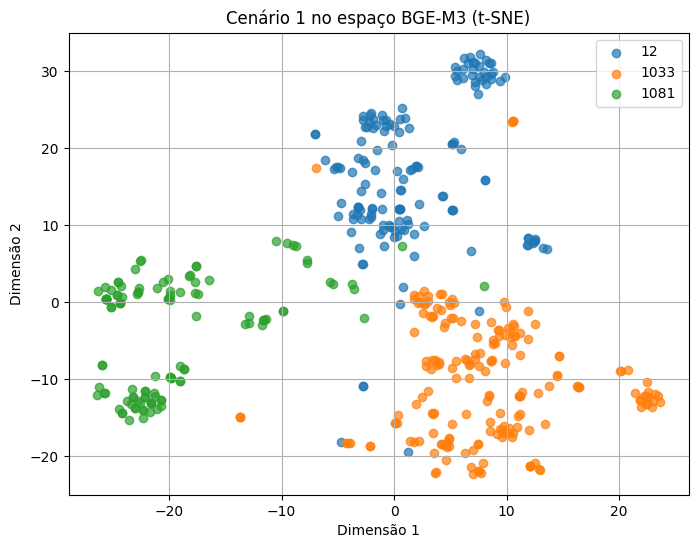

In [ ]:
# t-SNE on BGE-M3 space
reduzir_dimensionalidade(df1,"BGE-M3","theme_id", "Cenário 1 no espaço BGE-M3")

In [ ]:
# indice_silhouette on BGE-M3 space
indice_silhouette(df1["BGE-M3"],df1["theme_id"])

np.float32(0.12804863)

In [ ]:
# Performance dos classificadores no df1 on BGE space
tabela1_bge, resultados1_bge, hiperparametros1_bge = classificar(Xdf1_bge, ydf1, modelos)
display(tabela1_bge)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9761 ± 0.0129,0.9754 ± 0.0133,2.94 ± 1.41
RegLog,0.9739 ± 0.015,0.9739 ± 0.0153,0.2 ± 0.07
SVM-LIN,0.9788 ± 0.0115,0.9783 ± 0.0116,0.7 ± 0.15
SVM-RBF,0.974 ± 0.0149,0.9739 ± 0.0147,0.08 ± 0.0
k-NN,0.9505 ± 0.0121,0.9522 ± 0.0122,0.02 ± 0.03


In [ ]:
# Hiperparametros do cenario1 que levaram a avaliação mais robusta no espaço BGE.
hiperparametros1_bge

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.01,
  'clf__hidden_layer_sizes': (10, 10)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
# Aplica o processo estatistico nos resultados 1 do bge
processo_estatistico(resultados1_bge)

{'m_L': np.float64(0.9763831479410181),
 'm_NL': np.float64(0.9663574530895499),
 'Delta': np.float64(-0.010025694851468203),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### JINA

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
# df1_emb_jina = gera_embeddings(df1, "clean_text", "jinaai/jina-embeddings-v3", 1)
# Salvando a matriz de embeddings
# np.save("emb_df1_jina.npy", df1_emb_jina)

In [ ]:
# Carrega o modelo de embeddings salvo
df1["JINA"] = list(np.load("emb_df1_jina.npy"))

/tmp/ipykernel_271/4007191519.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["JINA"] = list(np.load("emb_df1_jina.npy"))


In [ ]:
df1.sample(2)

,theme_id,special_appeal_text,clean_text,BGE-M3,JINA
572,12,"feu, qualificada autos epígrafe, fine assina...",feu qualificada autos epígrafe fine assinados ...,"[-0.07440028, 0.014170119, -0.014026371, -0.00...","[0.11669922, -0.05126953, 0.06542969, 0.081542..."
3770,1081,"cabimento trata-se, síntese, julgado acolheu, ...",cabimento tratase síntese julgado acolheu aind...,"[0.026498059, 0.04115292, -0.030176368, 0.0303...","[0.0859375, -0.07324219, 0.02746582, 0.0986328..."


In [ ]:
# Variáveis de entrada no espaço JINA
Xdf1_jina = np.vstack(df1["JINA"].values)

In [ ]:
# Cálculo da similaridade média entre documentos do espaço JINA
smean_inter(Xdf1_jina,ydf1)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.820435
1,12,1081,17710,0.756004
2,1033,1081,21965,0.761220


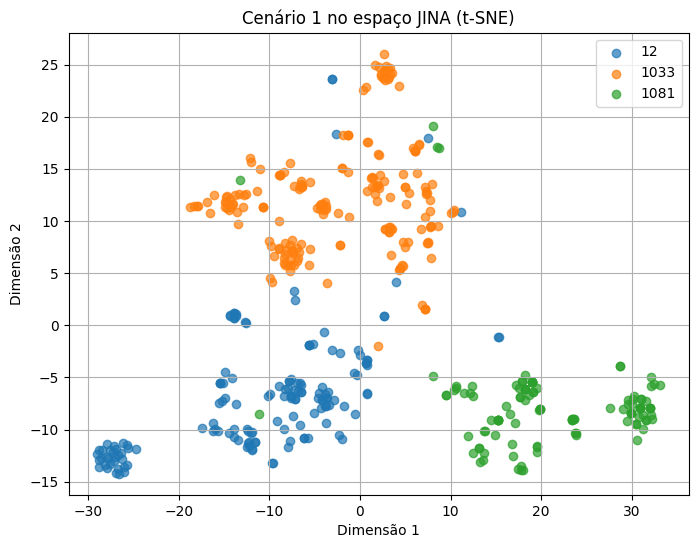

In [ ]:
# t-SNE on JINA space
reduzir_dimensionalidade(df1,"JINA","theme_id", "Cenário 1 no espaço JINA")

In [ ]:
# Silhouette-score on JINA space
indice_silhouette(df1["JINA"],df1["theme_id"])

np.float32(0.1508453)

In [ ]:
# Classificação com JINA
tabela1_jina, resultados1_jina, hiperparametros1_jina = classificar(Xdf1_jina, ydf1, modelos)
display(tabela1_jina)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9761 ± 0.0163,0.9768 ± 0.0164,0.34 ± 0.24
RegLog,0.9739 ± 0.0193,0.9746 ± 0.0191,0.29 ± 0.14
SVM-LIN,0.9786 ± 0.0171,0.9797 ± 0.0164,0.53 ± 0.1
SVM-RBF,0.9773 ± 0.0187,0.9783 ± 0.0179,0.08 ± 0.03
k-NN,0.9623 ± 0.0121,0.9616 ± 0.0122,0.01 ± 0.0


In [ ]:
# Hiperparams do cenario1 que levaram a avaliação mais robusta no espaço JINA.
hiperparametros1_jina

{'RegLog': {'clf__C': 0.1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
# Processo estatistico no espaço JINA
processo_estatistico(resultados1_jina)

{'m_L': np.float64(0.9762884390960582),
 'm_NL': np.float64(0.9713795721945067),
 'Delta': np.float64(-0.004908866901551567),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### STJ-iris-Legal-BERTencoder

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
# emb_df1_STJ_iris_LBERTenc = gera_embeddings(df1, "clean_text", "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0", 1)
# Salvando a matriz de embeddings
# np.save("emb_df1_STJ-iris-Legal-BERTencoder.npy", emb_df1_STJ_iris_LBERTenc)

In [ ]:
# Carrega o modelo de embeddings salvo
df1["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df1_STJ-iris-Legal-BERTencoder.npy"))

/tmp/ipykernel_271/1325294944.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df1_STJ-iris-Legal-BERTencoder.npy"))


In [ ]:
# Amostras aleatórias
df1.sample(2)

,theme_id,special_appeal_text,clean_text,BGE-M3,JINA,STJ-iris-Legal-BERTencoder
4723,1033,cabimento recurso recorrentes asseguram preenc...,cabimento recurso recorrentes asseguram preenc...,"[-0.04273987, 0.014266014, -0.009251865, -0.00...","[0.13769531, -0.061279297, 0.12402344, 0.05468...","[0.52371264, -0.7764261, -0.48588517, -0.26768..."
4816,1033,"cabimento acórdão caminhou, data vênia, sentid...",cabimento acórdão caminhou data vênia sentido ...,"[-0.015604682, -0.0005283962, -0.024418002, 0....","[0.10058594, -0.029418945, 0.055664062, 0.0756...","[0.123598814, -0.48672405, -0.35834908, -0.388..."


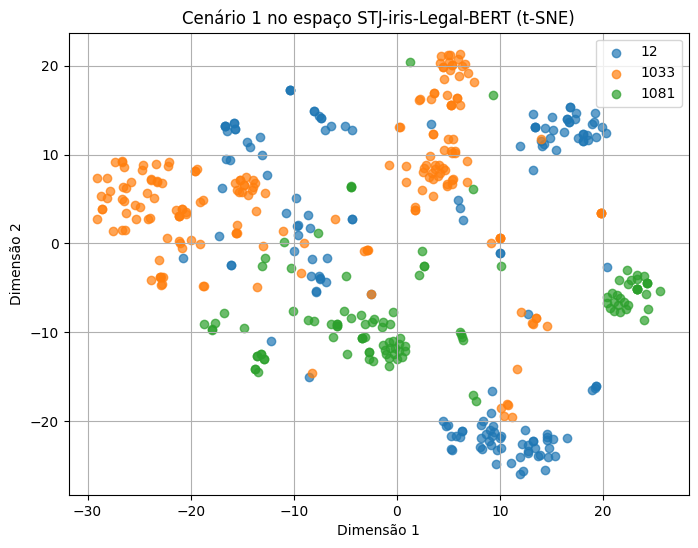

In [ ]:
# tSNE on STJ-iris-BERTLegal space
reduzir_dimensionalidade(df1,"STJ-iris-Legal-BERTencoder","theme_id", "Cenário 1 no espaço STJ-iris-Legal-BERT")

In [ ]:
# silhouette-score on STJ-iris-BERTLegal space
indice_silhouette(df1["STJ-iris-Legal-BERTencoder"],df1["theme_id"])

np.float32(0.062315427)

In [ ]:
# Variáveis de entrada do modelo STJ-iris-Legal-BERTencoder
Xdf1_stj = np.vstack(df1["STJ-iris-Legal-BERTencoder"].values)

In [ ]:
# Cálculo da similaridade média entre documentos do espaço STJ-iris-BERTLegal
smean_inter(Xdf1_stj,ydf1)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.879025
1,12,1081,17710,0.876158
2,1033,1081,21965,0.870221


In [ ]:
# Classificadores
tabela1_stj, resultados1_stj, hiperparametros1_stj = classificar(Xdf1_stj, ydf1, modelos)
display(tabela1_stj)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9138 ± 0.031,0.9138 ± 0.0322,0.78 ± 0.49
RegLog,0.9141 ± 0.0306,0.9145 ± 0.0304,0.16 ± 0.07
SVM-LIN,0.9175 ± 0.0238,0.9174 ± 0.0246,1.3 ± 0.17
SVM-RBF,0.9281 ± 0.0233,0.9261 ± 0.024,0.11 ± 0.02
k-NN,0.9015 ± 0.0345,0.9 ± 0.0349,0.01 ± 0.0


In [ ]:
hiperparametros1_stj

{'RegLog': {'clf__C': 10},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (10, 10)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
# Processo estatistico aplicado aos resultados da classificação do df1 no STJ space
processo_estatistico(resultados1_stj)

{'m_L': np.float64(0.9162244163422166),
 'm_NL': np.float64(0.9185253857651675),
 'Delta': np.float64(0.0023009694229508826),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### SERAFIM-335-PTPT

In [ ]:
# Gera embeddings do modelo da familia SERAFIM
#emb_df1_serafim = gera_embeddings(df1, "clean_text", "PORTULAN/serafim-335m-portuguese-pt-sentence-encoder", 1)
# Salvando os embeddings
#np.save("emb_df1_serafim.npy", emb_df1_serafim)

In [ ]:
# Carrega o modelo de embeddings salvo
df1["SERAFIM"] = list(np.load("emb_df1_serafim.npy"))

/tmp/ipykernel_271/655710448.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["SERAFIM"] = list(np.load("emb_df1_serafim.npy"))


In [ ]:
# Var de entrada para o modelo SERAFIM
Xdf1_serafim = np.vstack(df1["SERAFIM"].values)

In [ ]:
# Similaridade média entre docs representados segundo o modelo SERAFIM
smean_inter(Xdf1_serafim,ydf1)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.672896
1,12,1081,17710,0.619518
2,1033,1081,21965,0.622429


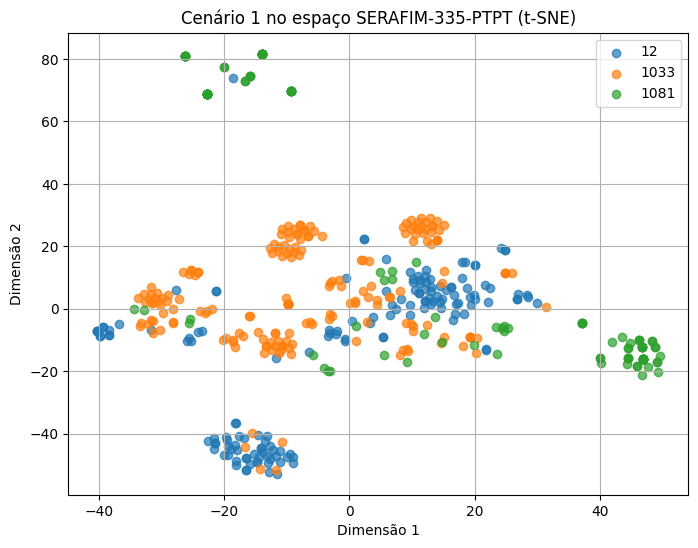

In [ ]:
# tSNE on SERAFIM space
reduzir_dimensionalidade(df1,"SERAFIM","theme_id", "Cenário 1 no espaço SERAFIM-335-PTPT")

In [ ]:
# silhouette-score on SERAFIM space
indice_silhouette(df1["SERAFIM"],df1["theme_id"])

In [ ]:
# Classificadores serafim
tabela1_serafim, resultados1_serafim, hiperparametros1_serafim = classificar(Xdf1_serafim, ydf1, modelos)
display(tabela1_serafim)

In [ ]:
hiperparametros1_serafim

In [ ]:
processo_estatistico(resultados1_serafim)

{'m_L': np.float64(0.8827424560672854),
 'm_NL': np.float64(0.8929544758671156),
 'Delta': np.float64(0.010212019799830219),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

#### Cenário 2: [1033,12,1081,1090,1046] - Similaridade Moderada

In [ ]:
# Cenario [1033,12,1081,1090,1046]
df2 = sappeal_clean[sappeal_clean["theme_id"].isin([1033,12,1081,1090,1046])]
df2_sizes = df2.value_counts("theme_id")
display(df2_sizes)
print("\nSize: ", df2.value_counts("theme_id").sum(), "amostras")

,count
theme_id,
1033,191
12,154
1090,148
1046,115
1081,115



Size:  723 amostras


In [ ]:
# Variável de saída do dataframe 2
ydf2 = df2["theme_id"].values

In [ ]:
# Impressão do texto plano dos temas do cenario 2
cenario2 = [1033,12,1081,1090,1046]
display(themes[themes["theme_id"].isin(cenario2)][["theme_id", "theme_text"]])

,theme_id,theme_text
10,12,Definir se a liquidação prévia do julgado é re...
122,1033,Interrupção do prazo prescricional para pleite...
127,1046,A possibilidade de fixação de honorários advoc...
143,1081,Definir se a demanda previdenciária cujo valor...
148,1090,"""1) se para provar a eficácia ou ineficácia do..."


In [ ]:
# Amostras aleatórias do df1
df2.sample(10)

,theme_id,special_appeal_text,clean_text
4618,1046,cabimento . 3 . omissão quanto fixação verba h...,cabimento omissão quanto fixação verba honorár...
4644,1046,"exmo . autor:: outros , , autos epígrafe...",exmo autor outros autos epígrafe inconformada ...
4607,1046,cabimento inestimável irrisório proveito econô...,cabimento inestimável irrisório proveito econô...
509,12,cabimento . . necessidade julgamento colegiado...,cabimento necessidade julgamento colegiado esg...
549,12,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...
3645,1081,cabimento presente recurso en-se alínea &; &; ...,cabimento presente recurso ense alínea inciso ...
572,12,"feu, qualificada autos epígrafe, fine assina...",feu qualificada autos epígrafe fine assinados ...
3326,1090,"cabimento recurso primeiramente, rejeitou emba...",cabimento recurso primeiramente rejeitou embar...
581,12,. . : sindicato trabalhadores educação univer...,sindicato trabalhadores educação universidade ...
4698,1033,cabimento recurso especial caracterização ques...,cabimento recurso especial caracterização ques...


##### BGE-M3

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
#emb_df2_bgem3 = gera_embeddings(df2, "clean_text", "BAAI/bge-m3", 1)
# Salvando a matriz de embeddings
#np.save("emb_df2_bge-m3.npy", emb_df2_bgem3)

Gerando embeddings no modelo:  BAAI/bge-m3


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/723 [00:00<?, ?it/s]

Tempo: 1450.35segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df2["BGE-M3"] = list(np.load("emb_df2_bge-m3.npy"))

/tmp/ipykernel_255/2035734360.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["BGE-M3"] = list(np.load("emb_df2_bge-m3.npy"))


In [ ]:
# Amostras aleatórias do dataframe 2
df2.sample(2)

,theme_id,special_appeal_text,clean_text,BGE-M3
4808,1033,cabimento recurso especial: recurso en-se alín...,cabimento recurso especial recurso ense alínea...,"[-0.03707217, 0.02666488, -0.034884356, 0.0168..."
4855,1033,cabimento recurso especial: recurso en-se alín...,cabimento recurso especial recurso ense alínea...,"[-0.044449195, 0.005472936, -0.020851498, 0.00..."


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf2_bge = np.vstack(df2["BGE-M3"].values)

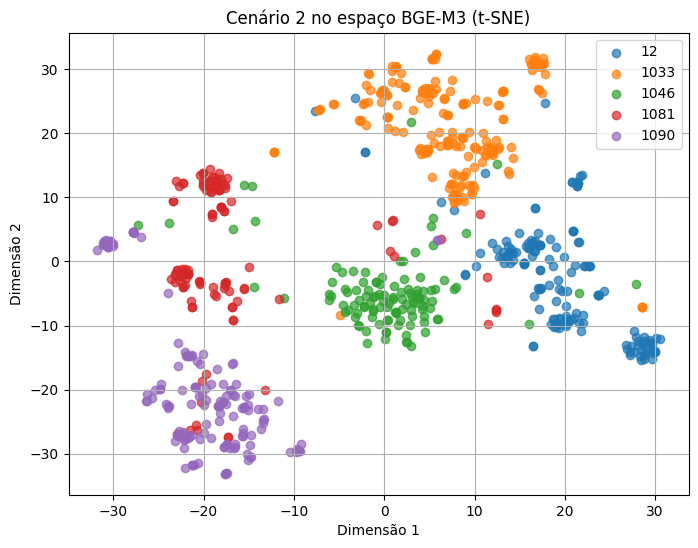

In [ ]:
# t-SNE on BGE-M3 space
reduzir_dimensionalidade(df2,"BGE-M3","theme_id", "Cenário 2 no espaço BGE-M3")

In [ ]:
indice_silhouette(df2["BGE-M3"],df2["theme_id"])

np.float32(0.09801914)

In [ ]:
# Cálculo da similaridade média entre documentos no espaço BGE-M3
smean_inter(Xdf2_bge,ydf2)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.805076
1,12,1046,17710,0.774837
2,12,1081,17710,0.764699
3,12,1090,22792,0.727837
4,1033,1046,21965,0.756880
5,1033,1081,21965,0.750942
6,1033,1090,28268,0.724824
7,1046,1081,13225,0.764122
8,1046,1090,17020,0.721766
9,1081,1090,17020,0.734034


In [ ]:
tabela2_bge, resultados2_bge, hiperparam2_bge = classificar(Xdf2_bge,ydf2,modelos)
display(tabela2_bge)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9605 ± 0.0119,0.9637 ± 0.0112,3.21 ± 0.91
RegLog,0.9544 ± 0.0134,0.9582 ± 0.0121,0.16 ± 0.03
SVM-LIN,0.9555 ± 0.0148,0.9591 ± 0.0139,3.27 ± 0.34
SVM-RBF,0.9539 ± 0.0134,0.9586 ± 0.0117,0.22 ± 0.04
k-NN,0.9351 ± 0.0168,0.9393 ± 0.0159,0.05 ± 0.02


In [ ]:
hiperparam2_bge

{'RegLog': {'clf__C': 10},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.01,
  'clf__hidden_layer_sizes': 20},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados2_bge)

{'m_L': np.float64(0.9549792135365873),
 'm_NL': np.float64(0.9486036135264327),
 'Delta': np.float64(-0.006375600010154581),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### JINA

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
#df2_emb_jina = gera_embeddings(df2, "clean_text", "jinaai/jina-embeddings-v3", 1)
# Salvando a matriz de embeddings
#np.save("emb_df2_jina.npy", df2_emb_jina)

Gerando embeddings no modelo:  jinaai/jina-embeddings-v3


modules.json:   0%|          | 0.00/378 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/464 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

custom_st.py: 0.00B [00:00, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/192 [00:00<?, ?B/s]

Batches:   0%|          | 0/723 [00:00<?, ?it/s]

Tempo: 1492.34segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df2["JINA"] = list(np.load("emb_df2_jina.npy"))

/tmp/ipykernel_255/3546346559.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["JINA"] = list(np.load("emb_df2_jina.npy"))


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf2_jina = np.vstack(df2["JINA"].values)

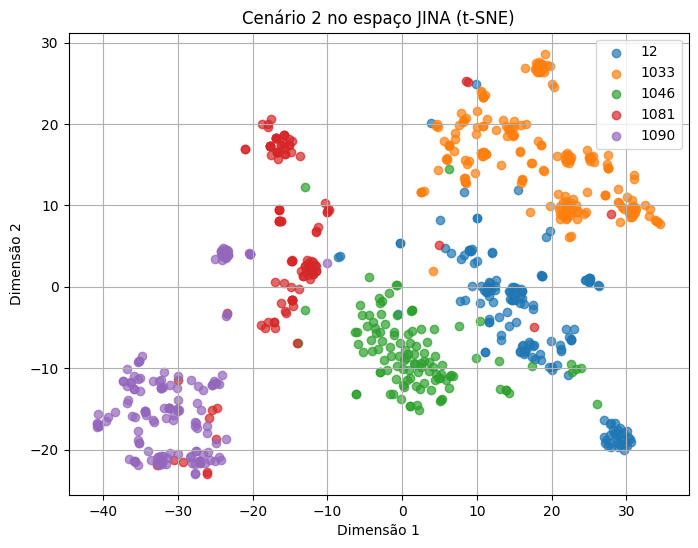

In [ ]:
reduzir_dimensionalidade(df2,"JINA","theme_id", "Cenário 2 no espaço JINA")

In [ ]:
indice_silhouette(df2["JINA"],df2["theme_id"])

np.float32(0.12785782)

In [ ]:
smean_inter(Xdf2_jina,ydf2)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.820435
1,12,1046,17710,0.761845
2,12,1081,17710,0.756004
3,12,1090,22792,0.695410
4,1033,1046,21965,0.756695
5,1033,1081,21965,0.761220
6,1033,1090,28268,0.713120
7,1046,1081,13225,0.750159
8,1046,1090,17020,0.696385
9,1081,1090,17020,0.737555


In [ ]:
tabela2_jina, resultados2_jina, hiperparam2_jina = classificar(Xdf2_jina,ydf2,modelos)
display(tabela2_jina)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9611 ± 0.0152,0.9637 ± 0.0146,2.94 ± 1.21
RegLog,0.9607 ± 0.0123,0.9632 ± 0.0121,0.67 ± 0.23
SVM-LIN,0.9596 ± 0.0131,0.9628 ± 0.0116,2.31 ± 0.21
SVM-RBF,0.9622 ± 0.0107,0.9655 ± 0.0107,0.18 ± 0.03
k-NN,0.9447 ± 0.0204,0.9471 ± 0.0191,0.03 ± 0.01


In [ ]:
hiperparam2_jina

{'RegLog': {'clf__C': 0.1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (50,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados2_jina)

{'m_L': np.float64(0.9601511391646553),
 'm_NL': np.float64(0.9566214744109448),
 'Delta': np.float64(-0.0035296647537105263),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### STJ-iris-Legal-BERTencoder


In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 2 de novo.
#emb_df2_STJ_iris_LBERTenc = gera_embeddings(df2, "clean_text", "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0", 1)
# Salvando a matriz de embeddings
#np.save("emb_df2_STJ-iris-Legal-BERTencoder.npy", emb_df2_STJ_iris_LBERTenc)

Gerando embeddings no modelo:  stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Invalid model-index. Not loading eval results into CardData.
Invalid model-index. Not loading eval results into CardData.


Batches:   0%|          | 0/723 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Carrega o modelo de embeddings salvo
df2["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df2_STJ-iris-Legal-BERTencoder.npy"))

/tmp/ipykernel_255/182614662.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df2_STJ-iris-Legal-BERTencoder.npy"))


In [ ]:
# Variáveis de entrada do modelo STJ-iris-Legal-BERTencoder
Xdf2_stj = np.vstack(df2["STJ-iris-Legal-BERTencoder"].values)

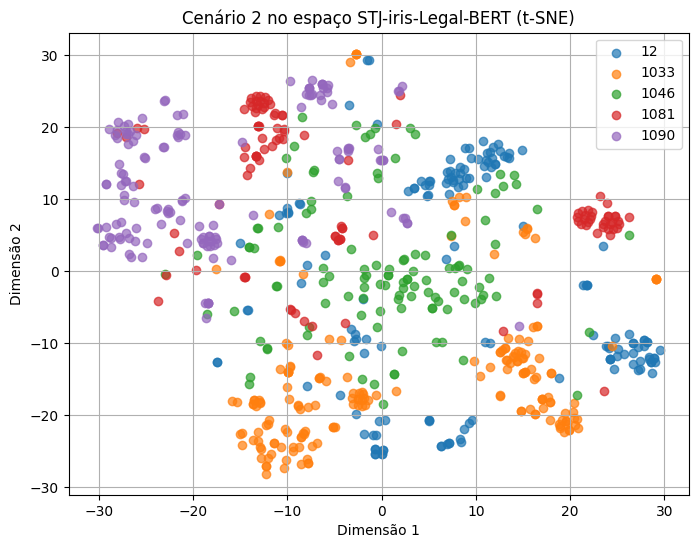

In [ ]:
reduzir_dimensionalidade(df2,"STJ-iris-Legal-BERTencoder","theme_id", "Cenário 2 no espaço STJ-iris-Legal-BERT")

In [ ]:
indice_silhouette(df2["STJ-iris-Legal-BERTencoder"],df2["theme_id"])

np.float32(0.02918521)

In [ ]:
smean_inter(Xdf2_stj,ydf2)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.879025
1,12,1046,17710,0.853738
2,12,1081,17710,0.876158
3,12,1090,22792,0.829245
4,1033,1046,21965,0.850775
5,1033,1081,21965,0.870221
6,1033,1090,28268,0.827517
7,1046,1081,13225,0.855610
8,1046,1090,17020,0.817710
9,1081,1090,17020,0.838327


In [ ]:
tabela2_stj, resultados2_stj, hiperparam2_stj = classificar(Xdf2_stj,ydf2,modelos)
display(tabela2_stj)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9021 ± 0.0254,0.9053 ± 0.0247,1.76 ± 0.24
RegLog,0.8966 ± 0.0288,0.8998 ± 0.0285,0.57 ± 0.09
SVM-LIN,0.891 ± 0.0231,0.8966 ± 0.0224,4.25 ± 0.56
SVM-RBF,0.9049 ± 0.0247,0.9094 ± 0.0247,0.25 ± 0.01
k-NN,0.8352 ± 0.0328,0.8483 ± 0.0289,0.03 ± 0.0


In [ ]:
hiperparam2_stj

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (256,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados2_stj)

{'m_L': np.float64(0.8937934779318121),
 'm_NL': np.float64(0.880935915464391),
 'Delta': np.float64(-0.012857562467421091),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### SERAFIM-335-PTPT

In [ ]:

# Gera embeddings do modelo da familia SERAFIM
#emb_df2_serafim = gera_embeddings(df2, "clean_text", "PORTULAN/serafim-335m-portuguese-pt-sentence-encoder", 1)
# Salvando os embeddings
#np.save("emb_df2_serafim.npy", emb_df2_serafim)

Gerando embeddings no modelo:  PORTULAN/serafim-335m-portuguese-pt-sentence-encoder


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Batches:   0%|          | 0/723 [00:00<?, ?it/s]

Tempo: 30.69segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df2["SERAFIM"] = list(np.load("emb_df2_serafim.npy"))

/tmp/ipykernel_255/3192173381.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["SERAFIM"] = list(np.load("emb_df2_serafim.npy"))


In [ ]:
# Variáveis de entrada do modelo STJ-iris-Legal-BERTencoder
Xdf2_serafim = np.vstack(df2["SERAFIM"].values)

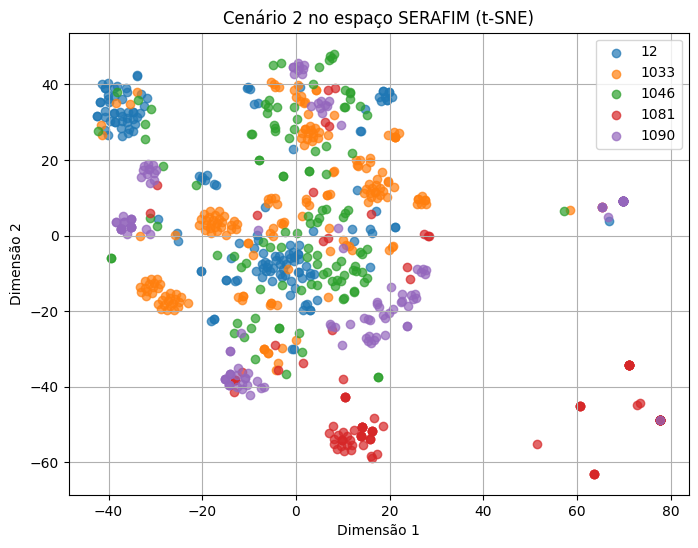

In [ ]:
reduzir_dimensionalidade(df2,"SERAFIM","theme_id", "Cenário 2 no espaço SERAFIM")

In [ ]:
indice_silhouette(df2["SERAFIM"],df2["theme_id"])

np.float32(0.03939843)

In [ ]:
smean_inter(Xdf2_serafim,ydf2)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.672896
1,12,1046,17710,0.620943
2,12,1081,17710,0.619518
3,12,1090,22792,0.628946
4,1033,1046,21965,0.623195
5,1033,1081,21965,0.622429
6,1033,1090,28268,0.620803
7,1046,1081,13225,0.593384
8,1046,1090,17020,0.585045
9,1081,1090,17020,0.615496


In [ ]:
tabela2_serafim, resultados2_serafim, hiperparametros2_serafim = classificar(Xdf2_serafim, ydf2, modelos)
display(tabela2_serafim)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.8523 ± 0.0316,0.8566 ± 0.0292,3.04 ± 1.5
RegLog,0.8506 ± 0.0354,0.8556 ± 0.0326,0.98 ± 0.39
SVM-LIN,0.8392 ± 0.0349,0.846 ± 0.0328,5.09 ± 0.4
SVM-RBF,0.8634 ± 0.0324,0.8667 ± 0.0314,0.25 ± 0.05
k-NN,0.8066 ± 0.0403,0.8225 ± 0.0351,0.03 ± 0.01


In [ ]:
hiperparametros2_serafim

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (256,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados2_serafim)

{'m_L': np.float64(0.8450229572399404),
 'm_NL': np.float64(0.8412250685678869),
 'Delta': np.float64(-0.00379788867205344),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

#### Cenário 3: [1033,12,1081,1090,1046,1140] - Similaridade Moderada

In [ ]:
# Cenario [1033,12,1081,1090,1046, 1140]
df3 = sappeal_clean[sappeal_clean["theme_id"].isin([1033,12,1081,1090,1046, 1140])]
df3_sizes = df3.value_counts("theme_id")
display(df3_sizes)
print("\nSize: ", df3.value_counts("theme_id").sum(), "amostras")

,count
theme_id,
1033,191
1140,166
12,154
1090,148
1081,115
1046,115



Size:  889 amostras


In [ ]:
# Impressão do texto plano dos temas do cenario 3
cenario3 = [1033,12,1081,1090,1046,1140]
display(themes[themes["theme_id"].isin(cenario3)][["theme_id", "theme_text"]])

,theme_id,theme_text
10,12,Definir se a liquidação prévia do julgado é re...
122,1033,Interrupção do prazo prescricional para pleite...
127,1046,A possibilidade de fixação de honorários advoc...
143,1081,Definir se a demanda previdenciária cujo valor...
148,1090,"""1) se para provar a eficácia ou ineficácia do..."
163,1140,"Definir, para efeito de adequação dos benefíci..."


In [ ]:
ydf3 = df3["theme_id"].values

In [ ]:
df3.sample(10)

,theme_id,special_appeal_text,clean_text
3525,1081,"cabimento recurso art . 1.029 cpc,, determina ...",cabimento recurso art cpc determina recorrente...
4707,1033,cabimento presente recurso especial (art . 105...,cabimento presente recurso especial art iii c ...
3320,1090,cabimento presente recurso en-se alínea &; &; ...,cabimento presente recurso ense alínea inciso ...
568,12,cabimento presente recurso especial (art . 105...,cabimento presente recurso especial art iii c ...
4884,1033,cabimento recurso especial: recurso en-se alín...,cabimento recurso especial recurso ense alínea...
6871,1090,"cabimento recurso art . 1.029 cpc,, determina ...",cabimento recurso art cpc determina recorrente...
2867,1140,"cabimento efeito, entende recorrente v. acórdã...",cabimento efeito entende recorrente v acórdão ...
552,12,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...
492,12,cabimento recurso recorrentes asseguram preenc...,cabimento recurso recorrentes asseguram preenc...
6894,1090,"cabimento recurso primeiramente, rejeitou emba...",cabimento recurso primeiramente rejeitou embar...


##### BGE-M3

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
#emb_df3_bgem3 = gera_embeddings(df3, "clean_text", "BAAI/bge-m3", 1)
# Salvando a matriz de embeddings
#np.save("emb_df3_bge-m3.npy", emb_df3_bgem3)

In [ ]:
# Carrega o modelo de embeddings salvo
df3["BGE-M3"] = list(np.load("emb_df3_bge-m3.npy"))

/tmp/ipykernel_255/109299026.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["BGE-M3"] = list(np.load("emb_df3_bge-m3.npy"))


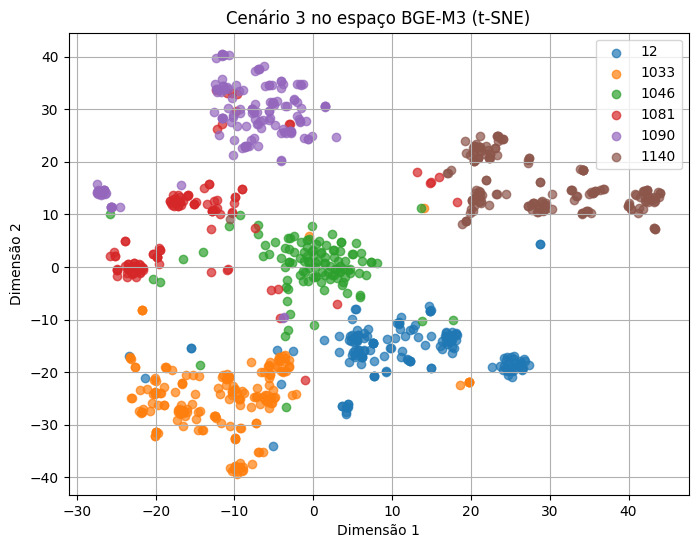

In [ ]:
reduzir_dimensionalidade(df3,"BGE-M3","theme_id", "Cenário 3 no espaço BGE-M3")

In [ ]:
indice_silhouette(df3["BGE-M3"],df3["theme_id"])

np.float32(0.12501177)

In [ ]:
Xdf3_bge = np.vstack(df3["BGE-M3"].values)

In [ ]:
smean_inter(Xdf3_bge,ydf3)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.805076
1,12,1046,17710,0.774837
2,12,1081,17710,0.764699
3,12,1090,22792,0.727837
4,12,1140,25564,0.782656
5,1033,1046,21965,0.756880
6,1033,1081,21965,0.750942
7,1033,1090,28268,0.724824
8,1033,1140,31706,0.758727
9,1046,1081,13225,0.764122


In [ ]:
tabela3_bge, resultados3_bge, hiperparametros3_bge = classificar(Xdf3_bge,ydf3,modelos)
display(tabela3_bge)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9648 ± 0.0126,0.9685 ± 0.0112,3.18 ± 1.24
RegLog,0.9625 ± 0.0103,0.9659 ± 0.0091,0.52 ± 0.19
SVM-LIN,0.9597 ± 0.0108,0.9637 ± 0.0095,4.61 ± 1.55
SVM-RBF,0.9592 ± 0.0121,0.964 ± 0.0101,0.33 ± 0.11
k-NN,0.9427 ± 0.0149,0.9476 ± 0.0139,0.06 ± 0.02


In [ ]:
hiperparametros3_bge

{'RegLog': {'clf__C': 0.1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados3_bge)

{'m_L': np.float64(0.9611150817302119),
 'm_NL': np.float64(0.9553220206727406),
 'Delta': np.float64(-0.005793061057471238),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### JINA

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 1 de novo.
#df3_emb_jina = gera_embeddings(df3, "clean_text", "jinaai/jina-embeddings-v3", 1)
# Salvando a matriz de embeddings
#np.save("emb_df3_jina.npy", df3_emb_jina)

In [ ]:
# Carrega o modelo de embeddings salvo
df3["JINA"] = list(np.load("emb_df3_jina.npy"))

/tmp/ipykernel_255/1391077230.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["JINA"] = list(np.load("emb_df3_jina.npy"))


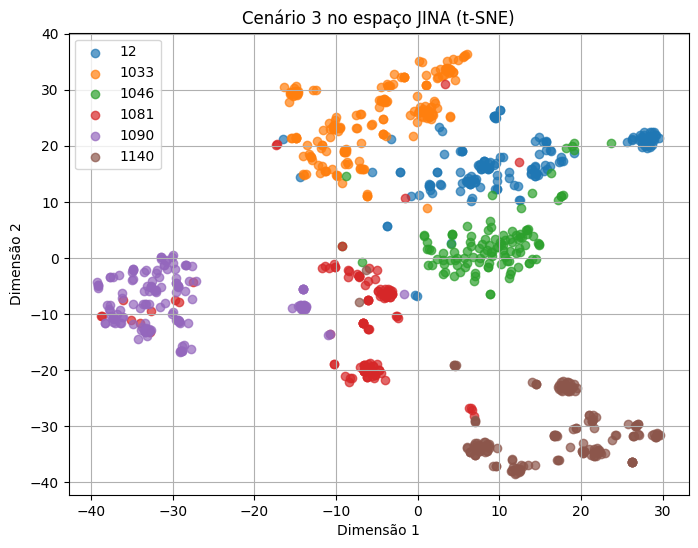

In [ ]:
reduzir_dimensionalidade(df3,"JINA","theme_id", "Cenário 3 no espaço JINA")

In [ ]:
indice_silhouette(df3["JINA"],df3["theme_id"])

np.float32(0.17118923)

In [ ]:
Xdf3_jina = np.vstack(df3["JINA"].values)

In [ ]:
smean_inter(Xdf3_jina,ydf3)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.820435
1,12,1046,17710,0.761845
2,12,1081,17710,0.756004
3,12,1090,22792,0.695410
4,12,1140,25564,0.751613
5,1033,1046,21965,0.756695
6,1033,1081,21965,0.761220
7,1033,1090,28268,0.713120
8,1033,1140,31706,0.731702
9,1046,1081,13225,0.750159


In [ ]:
tabela3_jina, resultados3_jina, hiperparametros3_jina = classificar(Xdf3_jina,ydf3,modelos)
display(tabela3_jina)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.966 ± 0.0117,0.9685 ± 0.011,3.53 ± 1.57
RegLog,0.9646 ± 0.01,0.9674 ± 0.0095,0.61 ± 0.22
SVM-LIN,0.9616 ± 0.0115,0.9652 ± 0.0104,3.37 ± 0.39
SVM-RBF,0.9648 ± 0.011,0.9685 ± 0.0106,0.21 ± 0.03
k-NN,0.9462 ± 0.0185,0.9502 ± 0.0168,0.05 ± 0.02


In [ ]:
hiperparametros3_jina

{'RegLog': {'clf__C': 0.1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados3_jina)

{'m_L': np.float64(0.9629043208941532),
 'm_NL': np.float64(0.9587563109192064),
 'Delta': np.float64(-0.004148009974946798),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### STJ-IRIS

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 2 de novo.
#emb_df3_STJ_iris_LBERTenc = gera_embeddings(df3, "clean_text", "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0", 1)
# Salvando a matriz de embeddings
#np.save("emb_df3_STJ-iris-Legal-BERTencoder.npy", emb_df3_STJ_iris_LBERTenc)

In [ ]:
# Carrega o modelo de embeddings salvo
df3["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df3_STJ-iris-Legal-BERTencoder.npy"))

/tmp/ipykernel_255/2592406457.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df3_STJ-iris-Legal-BERTencoder.npy"))


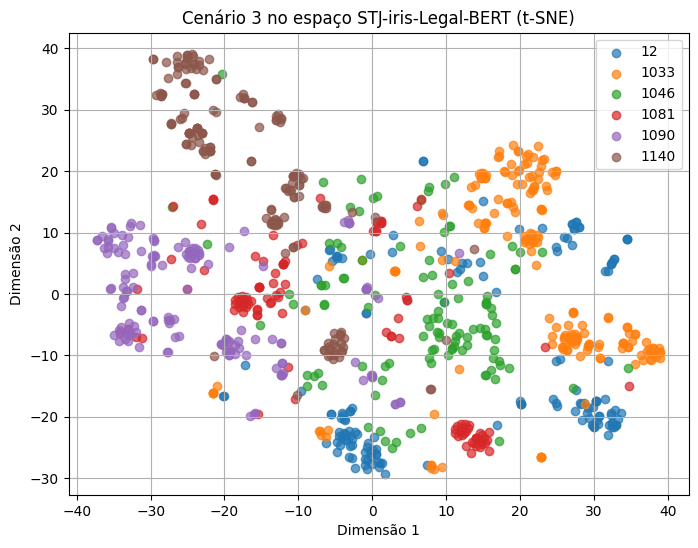

In [ ]:
reduzir_dimensionalidade(df3,"STJ-iris-Legal-BERTencoder","theme_id", "Cenário 3 no espaço STJ-iris-Legal-BERT")

In [ ]:
indice_silhouette(df3["STJ-iris-Legal-BERTencoder"],df3["theme_id"])

np.float32(0.038675636)

In [ ]:
Xdf3_stj = np.vstack(df3["STJ-iris-Legal-BERTencoder"].values)

In [ ]:
smean_inter(Xdf3_stj,ydf3)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.879025
1,12,1046,17710,0.853738
2,12,1081,17710,0.876158
3,12,1090,22792,0.829245
4,12,1140,25564,0.849924
5,1033,1046,21965,0.850775
6,1033,1081,21965,0.870221
7,1033,1090,28268,0.827517
8,1033,1140,31706,0.849089
9,1046,1081,13225,0.855610


In [ ]:
tabela3_stj, resultados3_stj, hiperparametros3_stj = classificar(Xdf3_stj,ydf3,modelos)
display(tabela3_stj)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9007 ± 0.0237,0.9067 ± 0.0225,2.0 ± 0.76
RegLog,0.8973 ± 0.0224,0.9034 ± 0.0216,0.78 ± 0.3
SVM-LIN,0.8994 ± 0.0238,0.9064 ± 0.0226,5.67 ± 0.48
SVM-RBF,0.9123 ± 0.0209,0.9184 ± 0.0202,0.37 ± 0.07
k-NN,0.8313 ± 0.0261,0.8487 ± 0.0223,0.04 ± 0.02


In [ ]:
hiperparametros3_stj

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados3_stj)

{'m_L': np.float64(0.8984911052291167),
 'm_NL': np.float64(0.8813781599199154),
 'Delta': np.float64(-0.017112945309201266),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### SERAFIM

In [ ]:
# Gera embeddings do modelo da familia SERAFIM
#emb_df3_serafim = gera_embeddings(df3, "clean_text", "PORTULAN/serafim-335m-portuguese-pt-sentence-encoder", 1)
# Salvando os embeddings
#np.save("emb_df3_serafim.npy", emb_df3_serafim)

Gerando embeddings no modelo:  PORTULAN/serafim-335m-portuguese-pt-sentence-encoder


Batches:   0%|          | 0/889 [00:00<?, ?it/s]

Tempo: 39.41segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df3["SERAFIM"] = list(np.load("emb_df3_serafim.npy"))

/tmp/ipykernel_255/2549258415.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df3["SERAFIM"] = list(np.load("emb_df3_serafim.npy"))


In [ ]:
df3.sample(3)

,theme_id,special_appeal_text,clean_text,BGE-M3,JINA,STJ-iris-Legal-BERTencoder,SERAFIM
4853,1033,cabimento - acordo enunciado 150 jurisprudênci...,cabimento acordo enunciado jurisprudência sumu...,"[-0.036973834, 0.017205592, -0.0139188925, 0.0...","[0.09375, -0.05029297, 0.061523438, 0.06738281...","[0.18277389, -0.7330713, -0.42402977, -0.47167...","[-0.280029, -0.19247708, 1.1424227, 0.1700899,..."
4889,1033,"cabimento embargos declaração, omissão, obscur...",cabimento embargos declaração omissão obscurid...,"[-0.049861033, 0.014025058, -0.0049955864, 0.0...","[0.12988281, -0.055419922, 0.12597656, 0.05078...","[0.08987959, -0.97060525, 0.08179978, -0.29927...","[-0.01667737, -0.038229838, 0.28830364, 0.4973..."
521,12,. . : sindicato trabalhadores educação univer...,sindicato trabalhadores educação universidade ...,"[-0.052694827, 0.01719804, 0.010926975, -0.016...","[0.106933594, -0.06591797, 0.11376953, 0.05053...","[0.38599825, -1.2008159, -0.537022, -0.1331306...","[1.4417909, -0.2511867, 0.4458786, 0.8474659, ..."


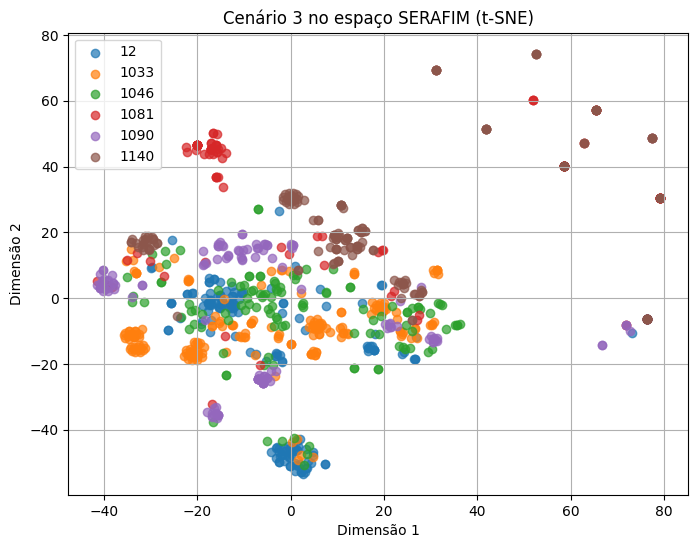

In [ ]:
reduzir_dimensionalidade(df3,"SERAFIM","theme_id", "Cenário 3 no espaço SERAFIM")

In [ ]:
indice_silhouette(df3["SERAFIM"],df3["theme_id"])

np.float32(0.031089392)

In [ ]:
Xdf3_serafim = np.vstack(df3["SERAFIM"].values)

In [ ]:
smean_inter(Xdf3_serafim,ydf3)

,classe_1,classe_2,n_pares,similaridade_media
0,12,1033,29414,0.672896
1,12,1046,17710,0.620943
2,12,1081,17710,0.619518
3,12,1090,22792,0.628946
4,12,1140,25564,0.612549
5,1033,1046,21965,0.623195
6,1033,1081,21965,0.622429
7,1033,1090,28268,0.620803
8,1033,1140,31706,0.619778
9,1046,1081,13225,0.593384


In [ ]:
tabela3_serafim, resultados3_serafim, hiperparametros3_serafim = classificar(Xdf3_serafim,ydf3,modelos)
display(tabela3_serafim)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.8055 ± 0.0274,0.818 ± 0.0268,8.42 ± 1.71
RegLog,0.8054 ± 0.0266,0.8161 ± 0.0266,1.42 ± 0.46
SVM-LIN,0.8021 ± 0.0237,0.8124 ± 0.024,8.55 ± 0.49
SVM-RBF,0.8208 ± 0.0238,0.8307 ± 0.026,0.35 ± 0.06
k-NN,0.7553 ± 0.0385,0.7801 ± 0.0342,0.04 ± 0.02


In [ ]:
hiperparametros3_serafim

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (256,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados3_serafim)

{'m_L': np.float64(0.8037052787120735),
 'm_NL': np.float64(0.7930579473350506),
 'Delta': np.float64(-0.010647331377022895),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

#### Cenário 4: [1033, 1140, 118] - Similaridade Baixa

In [ ]:
# Cenario [1033,1140,118]
df4 = sappeal_clean[sappeal_clean["theme_id"].isin([1033,1140,118])]
df4_sizes = df4.value_counts("theme_id")
display(df4_sizes)
print("\nSize: ", df4.value_counts("theme_id").sum(), "amostras")

,count
theme_id,
1033,191
118,167
1140,166



Size:  524 amostras


In [ ]:
# Impressão do texto plano dos temas do cenario 4
cenario4 = [1033,1140,118]
display(themes[themes["theme_id"].isin(cenario4)][["theme_id", "theme_text"]])

,theme_id,theme_text
16,118,Inclusão do ISS na base de cálculo do PIS e da...
122,1033,Interrupção do prazo prescricional para pleite...
163,1140,"Definir, para efeito de adequação dos benefíci..."


In [ ]:
df4.sample(10)

,theme_id,special_appeal_text,clean_text
4777,1033,secretaria assuntos jurídicos . . .: ai n.º ...,secretaria assuntos jurídicos ai n vem autos a...
2973,1140,cabimento prequesitonamento pré-questionamento...,cabimento prequesitonamento préquestionamento ...
7522,118,cabimento recurso opôs embargos declaração pr...,cabimento recurso opôs embargos declaração pro...
4703,1033,". sr. . ref . proc: outros, autos epígrafe, ...",sr ref proc outros autos epígrafe litigando fa...
2923,1140,". . . 2ª . , qualificada autos, vem respeitos...",qualificada autos vem respeitosamente presença...
7725,118,cabimento . re n 574.706 / pr . compensação vi...,cabimento re n pr compensação via administrati...
2958,1140,2ª : autor: réu: instituto nacional seguro so...,autor réu instituto nacional seguro social ins...
4780,1033,cabimento recurso especial: análise autos rest...,cabimento recurso especial análise autos resta...
2831,1140,cabimento cuida-se julgado deferiu parte autor...,cabimento cuidase julgado deferiu parte autora...
7694,118,cabimento recurso opôs embargos declaração pr...,cabimento recurso opôs embargos declaração pro...


In [ ]:
ydf4 = df4["theme_id"].values

##### BGE-M3

In [ ]:
# Geração dos embeddings contextuais do cenario 4 no espaço BGE-M3
#emb_df4_bge = gera_embeddings(df4, "clean_text", "BAAI/bge-m3", 1)
# Salvando os embeddings
#np.save("emb_df4_bge.npy", emb_df4_bge)

Gerando embeddings no modelo:  BAAI/bge-m3


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/524 [00:00<?, ?it/s]

Tempo: 1319.23segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df4["BGE-M3"] = list(np.load("emb_df4_bge.npy"))

/tmp/ipykernel_255/2674984033.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4["BGE-M3"] = list(np.load("emb_df4_bge.npy"))


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf4_bge = np.vstack(df4["BGE-M3"].values)

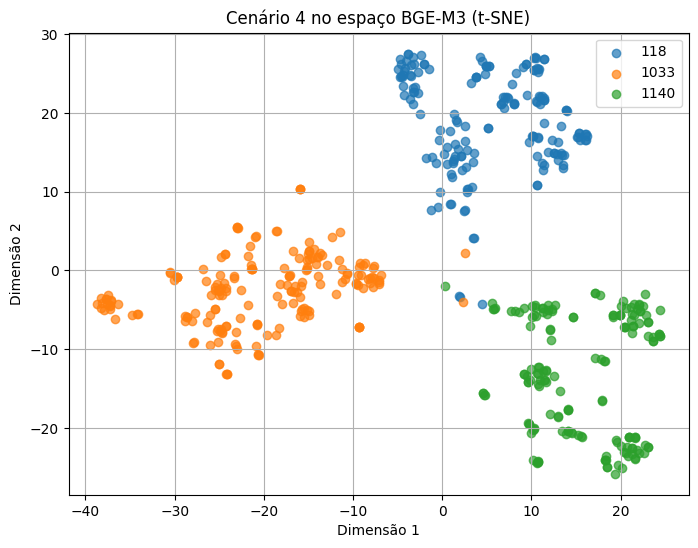

In [ ]:
reduzir_dimensionalidade(df4,"BGE-M3","theme_id", "Cenário 4 no espaço BGE-M3")

In [ ]:
indice_silhouette(df4["BGE-M3"],df4["theme_id"])

np.float32(0.19895414)

In [ ]:
smean_inter(Xdf4_bge,ydf4)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.754267
1,118,1140,27722,0.777604
2,1033,1140,31706,0.758727


In [ ]:
tabela4_bge, resultados4_bge, hiperparametros4_bge = classificar(Xdf4_bge,ydf4,modelos)
display(tabela4_bge)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9889 ± 0.0073,0.9892 ± 0.0071,1.35 ± 0.79
RegLog,0.9916 ± 0.0072,0.9917 ± 0.0071,0.22 ± 0.07
SVM-LIN,0.9909 ± 0.0069,0.9911 ± 0.0067,0.48 ± 0.14
SVM-RBF,0.9929 ± 0.0077,0.993 ± 0.0076,0.11 ± 0.03
k-NN,0.9801 ± 0.0106,0.9803 ± 0.0105,0.02 ± 0.0


In [ ]:
hiperparametros4_bge

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 11, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados4_bge)

{'m_L': np.float64(0.9912293743814911),
 'm_NL': np.float64(0.9875399818824778),
 'Delta': np.float64(-0.003689392499013233),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### JINA

In [ ]:
# Geração de embeddings contextuais do cenario 4 no espaço JINA
# emb_df4_jina = gera_embeddings(df4, "clean_text", "jinaai/jina-embeddings-v3", 1)
# Salvando os embeddings
# np.save("emb_df4_jina.npy", emb_df4_jina)

In [ ]:
# Carrega o modelo de embeddings salvo
df4["JINA"] = list(np.load("emb_df4_jina.npy"))

/tmp/ipykernel_255/2971145736.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4["JINA"] = list(np.load("emb_df4_jina.npy"))


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf4_jina = np.vstack(df4["JINA"].values)

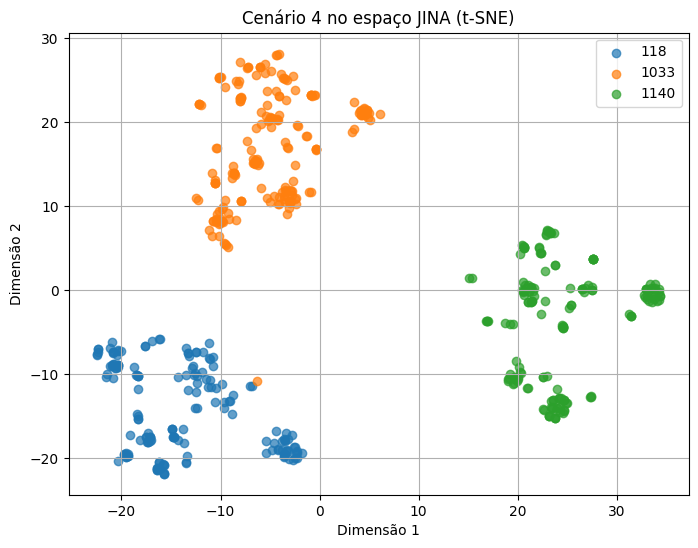

In [ ]:
reduzir_dimensionalidade(df4,"JINA","theme_id", "Cenário 4 no espaço JINA")

In [ ]:
smean_inter(Xdf4_jina,ydf4)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.737522
1,118,1140,27722,0.706270
2,1033,1140,31706,0.731702


In [ ]:
indice_silhouette(df4["JINA"],df4["theme_id"])

np.float32(0.30431837)

In [ ]:
smean_inter(Xdf4_jina,ydf4)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.737522
1,118,1140,27722,0.706270
2,1033,1140,31706,0.731702


In [ ]:
tabela4_jina, resultados4_jina, hiperparametros4_jina = classificar(Xdf4_jina,ydf4,modelos)
display(tabela4_jina)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,1.0 ± 0.0,1.0 ± 0.0,2.41 ± 1.19
RegLog,0.9993 ± 0.0026,0.9994 ± 0.0025,0.18 ± 0.04
SVM-LIN,1.0 ± 0.0,1.0 ± 0.0,0.26 ± 0.05
SVM-RBF,0.9987 ± 0.0035,0.9987 ± 0.0034,0.06 ± 0.01
k-NN,0.9944 ± 0.0048,0.9943 ± 0.0048,0.02 ± 0.0


In [ ]:
hiperparametros4_jina

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 5, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (10,)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados4_jina)

{'m_L': np.float64(0.9996680292332466),
 'm_NL': np.float64(0.9976795375973398),
 'Delta': np.float64(-0.001988491635906753),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### STJ-IRIS

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 2 de novo.
# emb_df4_STJ_iris_LBERTenc = gera_embeddings(df4, "clean_text", "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0", 1)
# Salvando a matriz de embeddings
# np.save("emb_df4_STJ-iris-Legal-BERTencoder.npy", emb_df4_STJ_iris_LBERTenc)

In [ ]:
# Carrega o modelo de embeddings salvo
df4["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df4_STJ-iris-Legal-BERTencoder.npy"))

/tmp/ipykernel_255/538314340.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df4_STJ-iris-Legal-BERTencoder.npy"))


In [ ]:
# Variáveis de entrada do modelo STJ-iris-Legal-BERTencoder
Xdf4_stj = np.vstack(df4["STJ-iris-Legal-BERTencoder"].values)

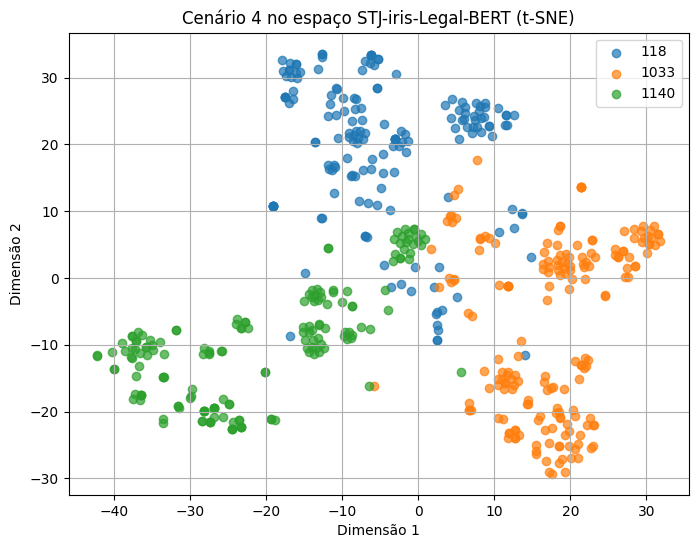

In [ ]:
reduzir_dimensionalidade(df4,"STJ-iris-Legal-BERTencoder","theme_id", "Cenário 4 no espaço STJ-iris-Legal-BERT")

In [ ]:
indice_silhouette(df4["STJ-iris-Legal-BERTencoder"],df4["theme_id"])

np.float32(0.11484452)

In [ ]:
smean_inter(Xdf4_stj,ydf4)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.851215
1,118,1140,27722,0.850918
2,1033,1140,31706,0.849089


In [ ]:
tabela4_stj, resultados4_stj, hiperparametros4_stj = classificar(Xdf4_stj,ydf4,modelos)
display(tabela4_stj)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9799 ± 0.0134,0.9797 ± 0.0134,0.63 ± 0.47
RegLog,0.9832 ± 0.0088,0.9829 ± 0.009,0.28 ± 0.1
SVM-LIN,0.9881 ± 0.0091,0.9879 ± 0.0092,0.88 ± 0.11
SVM-RBF,0.9893 ± 0.01,0.9892 ± 0.0101,0.1 ± 0.02
k-NN,0.9645 ± 0.0172,0.9651 ± 0.0168,0.02 ± 0.0


In [ ]:
hiperparametros4_stj

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.01,
  'clf__hidden_layer_sizes': (128,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados4_stj)

{'m_L': np.float64(0.9856651264026646),
 'm_NL': np.float64(0.9795649184511049),
 'Delta': np.float64(-0.006100207951559633),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### SERAFIM

In [ ]:
# Geração de embeddings contextuais do cenario 4 no espaço SERAFIM
#emb_df4_serafim = gera_embeddings(df4, "clean_text", "PORTULAN/serafim-335m-portuguese-pt-sentence-encoder", 1)
# Salvando os embeddings
#np.save("emb_df4_serafim.npy", emb_df4_serafim)

Gerando embeddings no modelo:  PORTULAN/serafim-335m-portuguese-pt-sentence-encoder


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Batches:   0%|          | 0/524 [00:00<?, ?it/s]

Tempo: 20.30segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df4["SERAFIM"] = list(np.load("emb_df4_serafim.npy"))

/tmp/ipykernel_255/4165698814.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df4["SERAFIM"] = list(np.load("emb_df4_serafim.npy"))


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf4_serafim = np.vstack(df4["SERAFIM"].values)

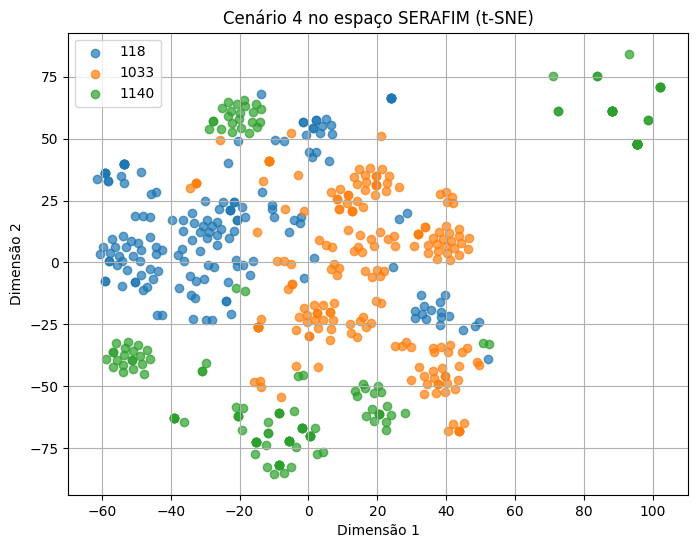

In [ ]:
reduzir_dimensionalidade(df4,"SERAFIM","theme_id", "Cenário 4 no espaço SERAFIM")

In [ ]:
indice_silhouette(df4["SERAFIM"],df4["theme_id"])

np.float32(0.07301141)

In [ ]:
smean_inter(Xdf4_serafim,ydf4)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.651141
1,118,1140,27722,0.626817
2,1033,1140,31706,0.619778


In [ ]:
tabela4_serafim, resultados4_serafim, hiperparametros4_serafim = classificar(Xdf4_serafim,ydf4,modelos)
display(tabela4_serafim)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9499 ± 0.0322,0.9498 ± 0.0319,0.82 ± 0.31
RegLog,0.9612 ± 0.0287,0.9613 ± 0.0287,0.29 ± 0.14
SVM-LIN,0.9682 ± 0.0246,0.9683 ± 0.0246,1.51 ± 0.21
SVM-RBF,0.9622 ± 0.0221,0.9619 ± 0.0225,0.1 ± 0.02
k-NN,0.9544 ± 0.0262,0.9543 ± 0.0263,0.02 ± 0.0


In [ ]:
hiperparametros4_serafim

{'RegLog': {'clf__C': 1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (256,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados4_serafim)

{'m_L': np.float64(0.9646826348230475),
 'm_NL': np.float64(0.9567726431824136),
 'Delta': np.float64(-0.007909991640633884),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

#### Cenário 5: [1033, 1140, 118, 1125] - Similaridade Moderada

In [ ]:
# Cenario [1033,1140,118,1125]
df5 = sappeal_clean[sappeal_clean["theme_id"].isin([1033,1140,118,1125])]
df5_sizes = df5.value_counts("theme_id")
display(df5_sizes)
print("\nSize: ", df5.value_counts("theme_id").sum(), "amostras")

,count
theme_id,
1033,191
118,167
1140,166
1125,138



Size:  662 amostras


In [ ]:
df5.sample(10)

,theme_id,special_appeal_text,clean_text
7609,118,cabimento presente recurso presente recurso es...,cabimento presente recurso presente recurso es...
2890,1140,cabimento cuida-se julgado deferiu parte autor...,cabimento cuidase julgado deferiu parte autora...
2772,1140,"cabimento recurso, entende recorrente decisões...",cabimento recurso entende recorrente decisões ...
3083,1125,cabimento recurso tela . 7 decerto questões en...,cabimento recurso tela decerto questões enfren...
4719,1033,previdenciária doutor vice- trf 2 . agravo ins...,previdenciária doutor vice trf agravo instrume...
4868,1033,"cabimento recurso fundamento alínea c, inc . i...",cabimento recurso fundamento alínea c inc iii ...
3120,1125,cabimento recurso especial face acórdão reform...,cabimento recurso especial face acórdão reform...
2962,1140,"cabimento efeito, entende recorrente violou di...",cabimento efeito entende recorrente violou dis...
3115,1125,cabimento recurso especial sempre petição recu...,cabimento recurso especial sempre petição recu...
4768,1033,cabimento legal presente recurso revela-se cab...,cabimento legal presente recurso revelase cabí...


In [ ]:
ydf5 = df5["theme_id"].values

In [ ]:
# Impressão do texto plano dos temas do cenario 5
cenario5 = [1033,1140,118,1125]
display(themes[themes["theme_id"].isin(cenario5)][["theme_id", "theme_text"]])

,theme_id,theme_text
16,118,Inclusão do ISS na base de cálculo do PIS e da...
122,1033,Interrupção do prazo prescricional para pleite...
159,1125,Possibilidade de exclusão do valor corresponde...
163,1140,"Definir, para efeito de adequação dos benefíci..."


##### BGE-M3

In [ ]:
# Gera embeddings do cenário 5 no espaço BGE-M3
# emb_df5_bge = gera_embeddings(df5, "clean_text", "BAAI/bge-m3", 1)
# Salvando os embeddings
# np.save("emb_df5_bge.npy", emb_df5_bge)

In [ ]:
# Carrega o modelo de embeddings salvo
df5["BGE-M3"] = list(np.load("emb_df5_bge.npy"))

/tmp/ipykernel_255/1906256903.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5["BGE-M3"] = list(np.load("emb_df5_bge.npy"))


In [ ]:
Xdf5_bge = np.vstack(df5["BGE-M3"].values)

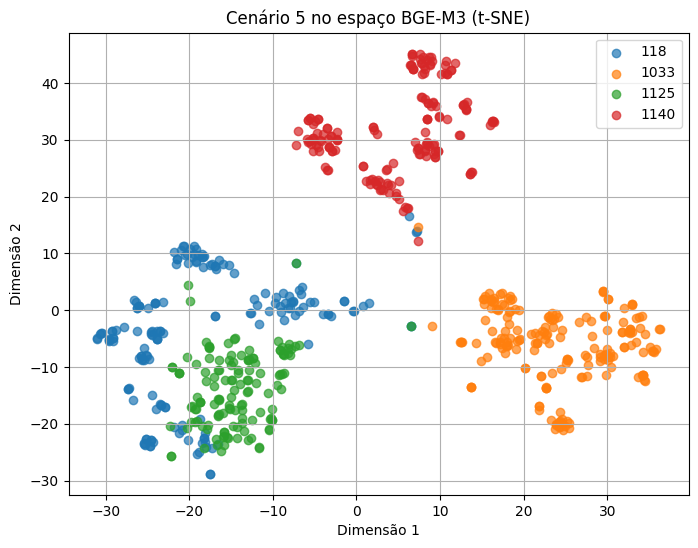

In [ ]:
reduzir_dimensionalidade(df5,"BGE-M3","theme_id", "Cenário 5 no espaço BGE-M3")

In [ ]:
indice_silhouette(df5["BGE-M3"],df5["theme_id"])

np.float32(0.14654402)

In [ ]:
smean_inter(Xdf5_bge,ydf5)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.754267
1,118,1125,23046,0.827018
2,118,1140,27722,0.777604
3,1033,1125,26358,0.741727
4,1033,1140,31706,0.758727
5,1125,1140,22908,0.772859


In [ ]:
tabela5_bge, resultados5_bge, hiperparametros5_bge = classificar(Xdf5_bge,ydf5,modelos)
display(tabela5_bge)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9666 ± 0.0171,0.9684 ± 0.0161,0.74 ± 0.48
RegLog,0.9731 ± 0.0148,0.9744 ± 0.0139,0.17 ± 0.08
SVM-LIN,0.9716 ± 0.0204,0.9729 ± 0.0194,1.46 ± 0.24
SVM-RBF,0.974 ± 0.0143,0.9754 ± 0.0135,0.18 ± 0.03
k-NN,0.9565 ± 0.017,0.9584 ± 0.0158,0.04 ± 0.01


In [ ]:
hiperparametros5_bge

{'RegLog': {'clf__C': 100},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 11, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.01,
  'clf__hidden_layer_sizes': (10,)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados5_bge)

{'m_L': np.float64(0.9723230726304191),
 'm_NL': np.float64(0.9659402231830775),
 'Delta': np.float64(-0.0063828494473415764),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### JINA

In [ ]:
# Gera embeddings do cenário 5
# emb_df5_jina = gera_embeddings(df5, "clean_text", "jinaai/jina-embeddings-v3", 1)
# Salvando os embeddings
# np.save("emb_df5_jina.npy", emb_df5_jina)

In [ ]:
# Carrega o modelo de embeddings salvo
df5["JINA"] = list(np.load("emb_df5_jina.npy"))

/tmp/ipykernel_255/3800979697.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5["JINA"] = list(np.load("emb_df5_jina.npy"))


In [ ]:
Xdf5_jina = np.vstack(df5["JINA"].values)

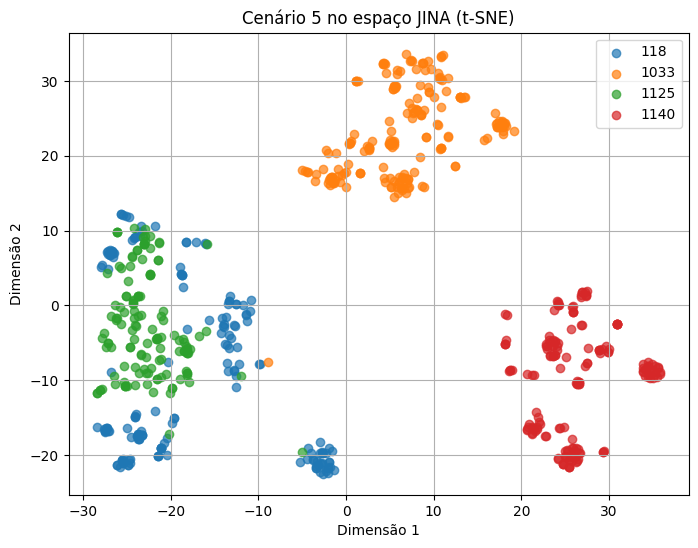

In [ ]:
reduzir_dimensionalidade(df5,"JINA","theme_id", "Cenário 5 no espaço JINA")

In [ ]:
indice_silhouette(df5["JINA"],df5["theme_id"])

np.float32(0.21563168)

In [ ]:
smean_inter(Xdf5_jina,ydf5)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.737522
1,118,1125,23046,0.833035
2,118,1140,27722,0.706270
3,1033,1125,26358,0.727574
4,1033,1140,31706,0.731702
5,1125,1140,22908,0.697106


In [ ]:
tabela5_jina, resultados5_jina, hiperparametros5_jina = classificar(Xdf5_jina,ydf5,modelos)
display(tabela5_jina)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9805 ± 0.0118,0.982 ± 0.0109,0.72 ± 0.39
RegLog,0.9813 ± 0.0105,0.9825 ± 0.0097,0.62 ± 0.23
SVM-LIN,0.9807 ± 0.0091,0.982 ± 0.0084,0.88 ± 0.1
SVM-RBF,0.9822 ± 0.011,0.9835 ± 0.0103,0.12 ± 0.02
k-NN,0.9749 ± 0.0131,0.9764 ± 0.012,0.03 ± 0.01


In [ ]:
hiperparametros5_jina

{'RegLog': {'clf__C': 0.1},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 5, 'clf__weights': 'uniform'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.001,
  'clf__hidden_layer_sizes': (10, 10)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados5_jina)

{'m_L': np.float64(0.9810341596336964),
 'm_NL': np.float64(0.9801898674820896),
 'Delta': np.float64(-0.0008442921516068624),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### STJ

In [ ]:
# Só executa para gerar a matriz de embeddings do dataframe 2 de novo.
#emb_df5_STJ_iris_LBERTenc = gera_embeddings(df5, "clean_text", "stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0", 1)
# Salvando a matriz de embeddings
#np.save("emb_df5_STJ-iris-Legal-BERTencoder.npy", emb_df5_STJ_iris_LBERTenc)

Gerando embeddings no modelo:  stjiris/bert-large-portuguese-cased-legal-mlm-sts-v1.0


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Invalid model-index. Not loading eval results into CardData.
Invalid model-index. Not loading eval results into CardData.


Batches:   0%|          | 0/662 [00:00<?, ?it/s]

Tempo: 83.65segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df5["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df5_STJ-iris-Legal-BERTencoder.npy"))

/tmp/ipykernel_255/2107301319.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5["STJ-iris-Legal-BERTencoder"] = list(np.load("emb_df5_STJ-iris-Legal-BERTencoder.npy"))


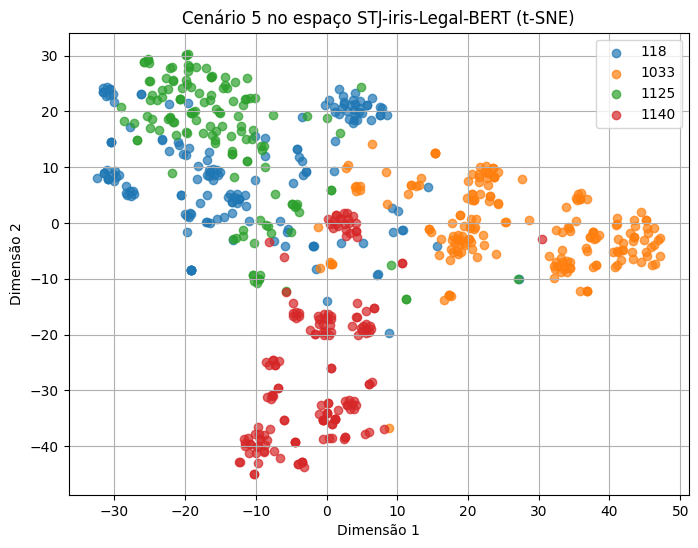

In [ ]:
reduzir_dimensionalidade(df5,"STJ-iris-Legal-BERTencoder","theme_id", "Cenário 5 no espaço STJ-iris-Legal-BERT")

In [ ]:
Xdf5_stj = np.vstack(df5["STJ-iris-Legal-BERTencoder"].values)

In [ ]:
indice_silhouette(df5["STJ-iris-Legal-BERTencoder"],df5["theme_id"])

np.float32(0.088743985)

In [ ]:
smean_inter(Xdf5_stj,ydf5)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.851215
1,118,1125,23046,0.862566
2,118,1140,27722,0.850918
3,1033,1125,26358,0.833281
4,1033,1140,31706,0.849089
5,1125,1140,22908,0.836273


In [ ]:
tabela5_stj, resultados5_stj, hiperparametros5_stj = classificar(Xdf5_stj,ydf5,modelos)
display(tabela5_stj)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.9543 ± 0.015,0.9559 ± 0.0147,2.17 ± 1.13
RegLog,0.9528 ± 0.0153,0.9544 ± 0.0149,0.17 ± 0.05
SVM-LIN,0.9532 ± 0.0137,0.9554 ± 0.0129,2.01 ± 0.23
SVM-RBF,0.9517 ± 0.0204,0.9539 ± 0.0195,0.17 ± 0.03
k-NN,0.9187 ± 0.0198,0.9228 ± 0.019,0.03 ± 0.01


In [ ]:
hiperparametros5_stj

{'RegLog': {'clf__C': 10},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'logistic',
  'clf__alpha': 0.0001,
  'clf__hidden_layer_sizes': (50,)},
 'SVM-RBF': {'clf__C': 10, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados5_stj)

{'m_L': np.float64(0.9530019264007705),
 'm_NL': np.float64(0.9400141600683375),
 'Delta': np.float64(-0.012987766332433037),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}

##### SERAFIM

In [ ]:
# Geração de embeddings contextuais do cenario 4 no espaço SERAFIM
#emb_df5_serafim = gera_embeddings(df5, "clean_text", "PORTULAN/serafim-335m-portuguese-pt-sentence-encoder", 1)
# Salvando os embeddings
#np.save("emb_df5_serafim.npy", emb_df5_serafim)

Gerando embeddings no modelo:  PORTULAN/serafim-335m-portuguese-pt-sentence-encoder


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/171 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Batches:   0%|          | 0/662 [00:00<?, ?it/s]

Tempo: 28.62segundos


In [ ]:
# Carrega o modelo de embeddings salvo
df5["SERAFIM"] = list(np.load("emb_df5_serafim.npy"))

/tmp/ipykernel_255/512502978.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df5["SERAFIM"] = list(np.load("emb_df5_serafim.npy"))


In [ ]:
# Variável de entrada do df1 no espaço BGE-M3
Xdf5_serafim = np.vstack(df5["SERAFIM"].values)

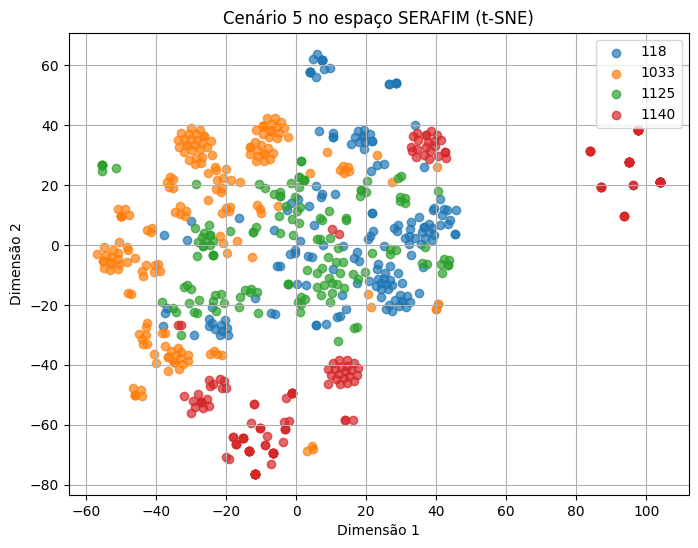

In [ ]:
reduzir_dimensionalidade(df5,"SERAFIM","theme_id", "Cenário 5 no espaço SERAFIM")

In [ ]:
smean_inter(Xdf5_serafim,ydf5)

,classe_1,classe_2,n_pares,similaridade_media
0,118,1033,31897,0.651141
1,118,1125,23046,0.653111
2,118,1140,27722,0.626817
3,1033,1125,26358,0.639917
4,1033,1140,31706,0.619778
5,1125,1140,22908,0.604403


In [ ]:
indice_silhouette(df5["SERAFIM"],df5["theme_id"])

np.float32(0.05173954)

In [ ]:
tabelas5_serafim, resultados5_serafim, hiperparametros5_serafim = classificar(Xdf5_serafim,ydf5,modelos)
display(tabelas5_serafim)

,F1-macro,Acurácia,Tempo (s)
Modelo,,,
MLP,0.8976 ± 0.0297,0.9023 ± 0.0281,1.51 ± 0.78
RegLog,0.9044 ± 0.0369,0.9088 ± 0.035,0.67 ± 0.19
SVM-LIN,0.8856 ± 0.0296,0.8912 ± 0.0283,3.12 ± 0.39
SVM-RBF,0.8999 ± 0.023,0.9038 ± 0.0228,0.18 ± 0.04
k-NN,0.888 ± 0.0221,0.8937 ± 0.0212,0.03 ± 0.01


In [ ]:
hiperparametros5_serafim

{'RegLog': {'clf__C': 0.01},
 'SVM-LIN': {'clf__C': 0.1},
 'k-NN': {'clf__n_neighbors': 3, 'clf__weights': 'distance'},
 'MLP': {'clf__activation': 'relu',
  'clf__alpha': 0.01,
  'clf__hidden_layer_sizes': (256,)},
 'SVM-RBF': {'clf__C': 1, 'clf__gamma': 'scale'}}

In [ ]:
processo_estatistico(resultados5_serafim)

{'m_L': np.float64(0.8950072076526161),
 'm_NL': np.float64(0.895156986290977),
 'Delta': np.float64(0.00014977863836085348),
 'Interpretacao': 'Boa separabilidade dos dados, sem vantagem significativa entre classificadores lineares e não lineares.'}